# Prédiction de Crises Épileptiques — Version Finale Corrigée
### Pipeline : PRÉDICTION (pas détection)
```
Alerte à t_a → crise prédite dans [t_a + SPH, t_a + SPH + SOP]
              = [t_a + 10min, t_a + 40min]
Si crise dans cet intervalle → VRAIE PRÉDICTION (délai AVANT la crise)
```

In [2]:
!pip install mne neurokit2 numpy scipy pandas scikit-learn matplotlib seaborn tqdm antropy -q


[notice] A new release of pip is available: 24.0 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import warnings, re, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns, mne, neurokit2 as nk
from scipy import signal as sp_signal
from scipy.stats import linregress, entropy as sp_entropy
from tqdm.auto import tqdm
from sklearn.feature_selection import SelectKBest, mutual_info_classif, VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, train_test_split, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
warnings.filterwarnings("ignore"); np.random.seed(42); random.seed(42)
sns.set_style("whitegrid"); plt.rcParams.update({'figure.dpi':120,'font.size':10})
_trapz = getattr(np,"trapezoid",None) or np.trapz
print("✓ Imports")

✓ Imports


c:\Users\GIGABYTE\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
DATA_ROOT = Path(".")
MAX_PAT   = 20
WIN_S     = 120; OVL_S = 60
SPH_S     = 600    # CORRECTION : 10min (standard littérature, pas 15min)
SOP_S     = 1800   # 30min — fenêtre de prédiction valide
BG_DUR    = 7200   # CORRECTION : 2h (assez pour HRV spectrale fiable)
BG_DIST   = 10800  # 3h distance min crise-BG
SEED      = 42
N_CONSEC  = 3      # CORRECTION : 3 consécutives (standard, pas 5)
COOLDOWN  = 1800   # 30min entre alertes
MIN_RP=60; MIN_RR=40; HR_LO=40; HR_HI=150
VAR_THR=0.03; BP_L=0.5; BP_H=40.0; NOTCH=50.0
TR_R=0.70; VA_R=0.10; TE_R=0.20

# On teste automatiquement plusieurs seuils et on retient le meilleur
print(f"  SPH={SPH_S//60}min | SOP={SOP_S//60}min | BG={BG_DUR//60}min")
print(f"  Alerte : {N_CONSEC} consécutives | Cooldown={COOLDOWN//60}min")


  SPH=10min | SOP=30min | BG=120min
  Alerte : 3 consécutives | Cooldown=30min


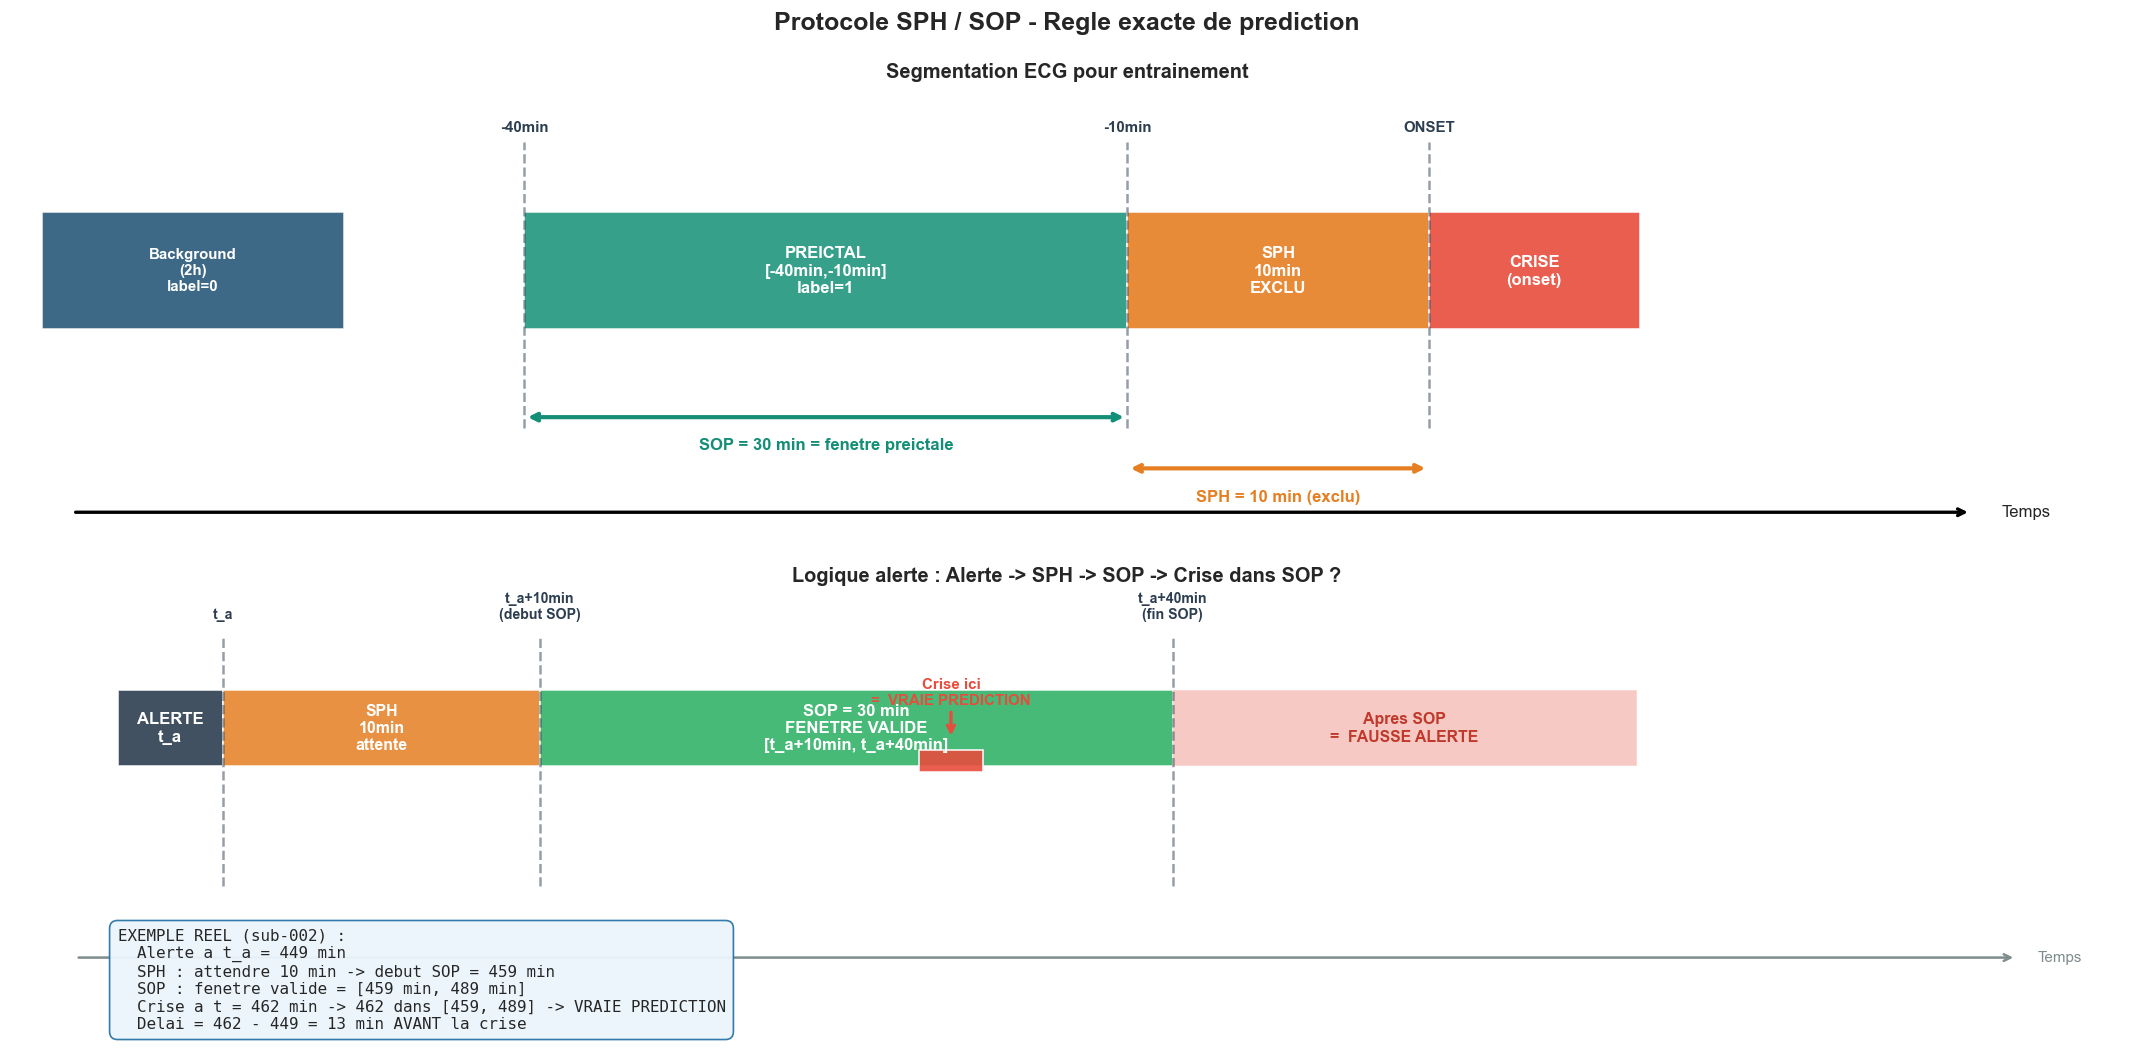

REGLE EXACTE SPH / SOP
  SPH = 600s = 10min | SOP = 1800s = 30min

  ETAPE 1 : 3 fenetres consecutives >= seuil -> ALERTE a t_a
  ETAPE 2 : SPH = 10min d'attente -> debut SOP = t_a + 10min
  ETAPE 3 : SOP = 30min de fenetre valide = [t_a+10min, t_a+40min]
  ETAPE 4 : Crise dans SOP -> VRAIE PREDICTION  |  Sinon -> FAUSSE ALERTE

  Dans eval_patient() :
    vs = ta + SPH_S          # = t_a + 600s = debut surveillance
    ve = ta + SPH_S + SOP_S  # = t_a + 2400s = fin surveillance
    if vs <= onset_crise <= ve -> VRAIE PREDICTION

-----------------------------------------------------------------
SEGMENTATION (donnees d'entrainement)
-----------------------------------------------------------------
  Preictal = [-40min, -10min] par rapport a la crise
  = ONSET - 2400s jusqu'a ONSET - 600s
  => Label = 1 (preictal)
  SPH in avant crise] = EXCLU (trop proche = detection, pas prediction)
  Background = 2h le plus eloigne de toutes les crises => Label = 0


In [5]:
# Schema SPH / SOP - Regle correcte + Exemple concret
fig, axes = plt.subplots(2, 1, figsize=(18, 9))
fig.suptitle('Protocole SPH / SOP - Regle exacte de prediction', fontsize=15, fontweight='bold')

# === PANNEAU 1 : Segmentation pour entrainement ===
ax = axes[0]
ax.set_xlim(-5, 65); ax.set_ylim(-1.2, 5)
ax.axis('off')
ax.set_title('Segmentation ECG pour entrainement', fontsize=12, fontweight='bold')
y = 2.5

# Background
ax.barh(y, 10, left=-4, height=1.6, color='#1B4F72', alpha=0.85)
ax.text(1, y, 'Background\n(2h)\nlabel=0', ha='center', va='center', fontsize=9, color='white', fontweight='bold')

# Preictal = [-40min, -10min]
ax.barh(y, 20, left=12, height=1.6, color='#148F77', alpha=0.85)
ax.text(22, y, 'PREICTAL\n[-40min,-10min]\nlabel=1', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# SPH (exclu)
ax.barh(y, 10, left=32, height=1.6, color='#E67E22', alpha=0.9)
ax.text(37, y, 'SPH\n10min\nEXCLU', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Crise
ax.barh(y, 7, left=42, height=1.6, color='#E74C3C', alpha=0.9)
ax.text(45.5, y, 'CRISE\n(onset)', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Fleche temps
ax.annotate('', xy=(60, -0.8), xytext=(-3, -0.8),
            arrowprops=dict(arrowstyle='->', color='black', lw=2))

ax.text(61, -0.8, 'Temps', fontsize=10, va='center', ha='left')
for xp, lbl in [(12, '-40min'), (32, '-10min'), (42, 'ONSET')]:
    ax.axvline(xp, ymin=0.25, ymax=0.88, color='#2C3E50', ls='--', alpha=0.5, lw=1.5)
    ax.text(xp, 4.4, lbl, ha='center', fontsize=9, fontweight='bold', color='#2C3E50')

ax.annotate('', xy=(32, 0.5), xytext=(12, 0.5), arrowprops=dict(arrowstyle='<->', color='#148F77', lw=2.5))
ax.text(22, 0.05, 'SOP = 30 min = fenetre preictale', ha='center', fontsize=10, fontweight='bold', color='#148F77')
ax.annotate('', xy=(42, -0.2), xytext=(32, -0.2), arrowprops=dict(arrowstyle='<->', color='#E67E22', lw=2.5))
ax.text(37, -0.65, 'SPH = 10 min (exclu)', ha='center', fontsize=10, fontweight='bold', color='#E67E22')

# === PANNEAU 2 : Logique alerte en temps reel ===
ax2 = axes[1]
ax2.set_xlim(0, 100); ax2.set_ylim(-2.8, 5.5)
ax2.axis('off')
ax2.set_title('Logique alerte : Alerte -> SPH -> SOP -> Crise dans SOP ?', fontsize=12, fontweight='bold')
y2 = 3.0

# Alerte
ax2.barh(y2, 5, left=5, height=1.4, color='#2C3E50', alpha=0.9)
ax2.text(7.5, y2, 'ALERTE\nt_a', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# SPH attente
ax2.barh(y2, 15, left=10, height=1.4, color='#E67E22', alpha=0.85)
ax2.text(17.5, y2, 'SPH\n10min\nattente', ha='center', va='center', fontsize=9.5, color='white', fontweight='bold')

# SOP fenetre valide
ax2.barh(y2, 30, left=25, height=1.4, color='#27AE60', alpha=0.85)
ax2.text(40, y2, 'SOP = 30 min\nFENETRE VALIDE\n[t_a+10min, t_a+40min]', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Crise dans SOP -> vraie prediction
ax2.barh(y2-0.6, 3, left=43, height=0.4, color='#E74C3C', alpha=0.9)
ax2.text(44.5, y2+0.65, 'Crise ici\n=  VRAIE PREDICTION', ha='center', va='center', fontsize=9, color='#E74C3C', fontweight='bold')
ax2.annotate('', xy=(44.5, y2-0.2), xytext=(44.5, y2+0.35), arrowprops=dict(arrowstyle='->', color='#E74C3C', lw=2))

# Apres SOP
ax2.barh(y2, 22, left=55, height=1.4, color='#E74C3C', alpha=0.3)
ax2.text(66, y2, 'Apres SOP\n=  FAUSSE ALERTE', ha='center', va='center', fontsize=9.5, color='#C0392B', fontweight='bold')

for xp, lbl in [(10, 't_a'), (25, 't_a+10min\n(debut SOP)'), (55, 't_a+40min\n(fin SOP)')]:
    ax2.axvline(xp, ymin=0.35, ymax=0.90, color='#2C3E50', ls='--', alpha=0.5, lw=1.5)
    ax2.text(xp, 5.0, lbl, ha='center', fontsize=8.5, fontweight='bold', color='#2C3E50')

ax2.annotate('', xy=(95, -1.2), xytext=(3, -1.2),
            arrowprops=dict(arrowstyle='->', color='#7F8C8D', lw=1.5))

ax2.text(96, -1.2, 'Temps', fontsize=9, color='#7F8C8D', va='center', ha='left')
# Exemple concret
exemple_txt = 'EXEMPLE REEL (sub-002) :\n  Alerte a t_a = 449 min\n  SPH : attendre 10 min -> debut SOP = 459 min\n  SOP : fenetre valide = [459 min, 489 min]\n  Crise a t = 462 min -> 462 dans [459, 489] -> VRAIE PREDICTION\n  Delai = 462 - 449 = 13 min AVANT la crise'
ax2.text(5, -2.5, exemple_txt, fontsize=9.5, fontfamily='monospace',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#EBF5FB', edgecolor='#2874A6', alpha=0.95))

plt.tight_layout(pad=1.5)
plt.savefig('sph_sop_correct.png', dpi=150, bbox_inches='tight')
plt.show()

# Affichage texte
print('=' * 65)
print('REGLE EXACTE SPH / SOP')
print('=' * 65)
print(f'  SPH = {SPH_S}s = {SPH_S//60}min | SOP = {SOP_S}s = {SOP_S//60}min')
print()
print('  ETAPE 1 : 3 fenetres consecutives >= seuil -> ALERTE a t_a')
print(f'  ETAPE 2 : SPH = {SPH_S//60}min d\'attente -> debut SOP = t_a + {SPH_S//60}min')
print(f'  ETAPE 3 : SOP = {SOP_S//60}min de fenetre valide = [t_a+{SPH_S//60}min, t_a+{(SPH_S+SOP_S)//60}min]')
print('  ETAPE 4 : Crise dans SOP -> VRAIE PREDICTION  |  Sinon -> FAUSSE ALERTE')
print()
print('  Dans eval_patient() :')
print(f'    vs = ta + SPH_S          # = t_a + {SPH_S}s = debut surveillance')
print(f'    ve = ta + SPH_S + SOP_S  # = t_a + {SPH_S+SOP_S}s = fin surveillance')
print('    if vs <= onset_crise <= ve -> VRAIE PREDICTION')
print()
print('-' * 65)
print('SEGMENTATION (donnees d\'entrainement)')
print('-' * 65)
print(f'  Preictal = [-{(SPH_S+SOP_S)//60}min, -{SPH_S//60}min] par rapport a la crise')
print(f'  = ONSET - {SPH_S+SOP_S}s jusqu\'a ONSET - {SPH_S}s')
print('  => Label = 1 (preictal)')
print(f'  SPH [{SPH_S//60}min avant crise] = EXCLU (trop proche = detection, pas prediction)')
print('  Background = 2h le plus eloigne de toutes les crises => Label = 0')


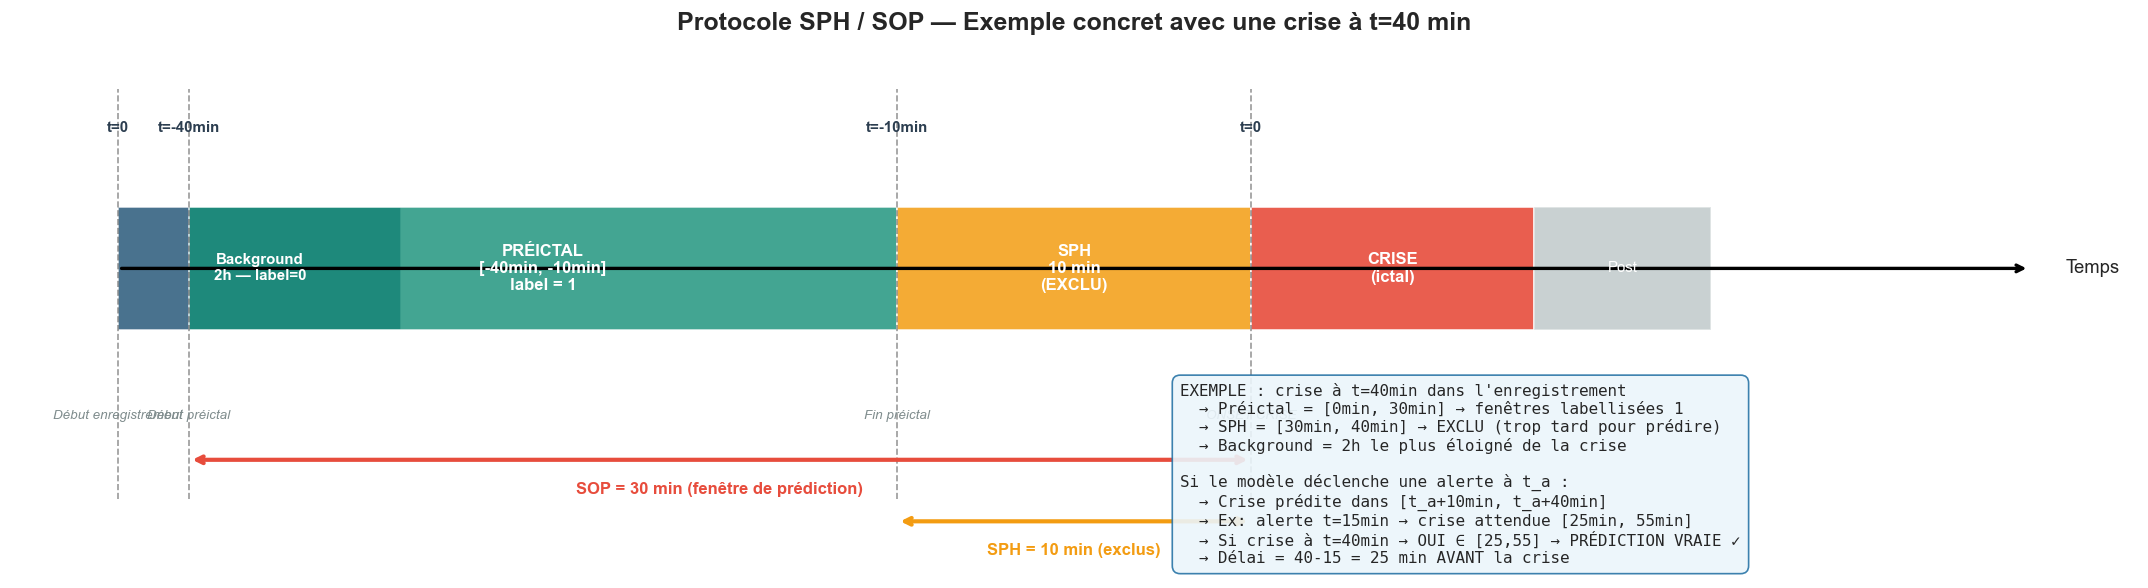


══════════════════════════════════════════════════════════════════════
RÈGLES SPH / SOP APPLIQUÉES DANS CE PIPELINE
══════════════════════════════════════════════════════════════════════
  SPH (Seizure Prediction Horizon) = 600s = 10 min
  → Exclut les 10 dernières minutes avant la crise
  → Si on alertait dans cette zone, ce serait de la DÉTECTION, pas de la PRÉDICTION

  SOP (Seizure Occurrence Period) = 1800s = 30 min
  → Fenêtre dans laquelle le modèle est évalué
  → Le préictal est extrait dans [-40min, -10min] avant la crise

  Alerte à t_a → crise prédite dans [t_a + 10min, t_a + 40min]
  → Si une crise arrive dans cet intervalle → VRAIE PRÉDICTION
  → Sinon → FAUSSE ALERTE

  Background = 7200s = 120 min
  → Segment le plus éloigné de toutes les crises (distance max)
  → BG_DIST minimum = 10800s = 180 min

  Fenêtre glissante = 120s = 2 min
  → Overlap = 60s = 1 min (50%)
  → Step = 60s → 1 nouvelle proba par minute
  → Sur 18h : 1080 fenêtres

  Alerte = 3 fenêtres consécutiv

In [6]:
# ════════════════════════════════════════════════════════════════
# SCHÉMA SPH / SOP — Exemple concret pour comprendre la prédiction
# ════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(18, 5))
ax.set_xlim(-5, 55); ax.set_ylim(-2, 5.5)
ax.axis('off')
ax.set_title("Protocole SPH / SOP — Exemple concret avec une crise à t=40 min",
             fontsize=15, fontweight='bold', pad=20)

# Timeline principale
ax.annotate('', xy=(52, 2.5), xytext=(-2, 2.5),
            arrowprops=dict(arrowstyle='->', color='black', lw=2))
ax.text(53, 2.5, 'Temps', fontsize=11, va='center')

# ── Zones colorées ──
zones = [
    (-2, 8,   '#2874A6', 'Background\n(2h)', 0.3),
    (8, 20,  '#D5F5E3', '', 0.15),
    (0, 20,  '#148F77', 'PRÉICTAL\n[-40, -10] min\nlabel = 1', 0.35),
    (20, 30, '#F39C12', 'SPH\n10 min\n(exclu)', 0.4),
    (30, 40, '#E74C3C', 'CRISE\n(ictal)', 0.5),
    (40, 50, '#95A5A6', 'Post-crise', 0.2),
]
# Simplified: draw the key zones
rects = [
    (-2, 10, '#1B4F72', 'Background (2h)\nlabel = 0'),
    (10, 10, '#FFFFFF', ''),       # zone libre
    (0, 20, '#148F77', 'PRÉICTAL [-40, -10]min\nlabel = 1'),
    (30, 10, '#F39C12', 'SPH 10min\n(exclu)'),
    (40, 8,  '#E74C3C', 'CRISE'),
    (48, 5,  '#95A5A6', 'Post'),
]

y = 2.5
# Background
ax.barh(y, 8, left=-2, height=1.8, color='#1B4F72', alpha=0.8)
ax.text(2, y, 'Background\n2h — label=0', ha='center', va='center', fontsize=9, color='white', fontweight='bold')

# Préictal
ax.barh(y, 20, left=0, height=1.8, color='#148F77', alpha=0.8)
ax.text(10, y, 'PRÉICTAL\n[-40min, -10min]\nlabel = 1', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# SPH
ax.barh(y, 10, left=20, height=1.8, color='#F39C12', alpha=0.85)
ax.text(25, y, 'SPH\n10 min\n(EXCLU)', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Crise
ax.barh(y, 8, left=30, height=1.8, color='#E74C3C', alpha=0.9)
ax.text(34, y, 'CRISE\n(ictal)', ha='center', va='center', fontsize=10, color='white', fontweight='bold')

# Post-crise
ax.barh(y, 5, left=38, height=1.8, color='#95A5A6', alpha=0.5)
ax.text(40.5, y, 'Post', ha='center', va='center', fontsize=9, color='white')

# Annotations avec minutage
annotations = [
    (-2, 't=0', 'Début enregistrement'),
    (0,  't=-40min', 'Début préictal'),
    (20, 't=-10min', 'Fin préictal'),
    (30, 't=0', 'ONSET CRISE'),
]
for xp, label, desc in annotations:
    ax.axvline(xp, ymin=0.15, ymax=0.95, color='black', ls='--', alpha=0.4, lw=1)
    ax.text(xp, 4.5, label, ha='center', fontsize=9, fontweight='bold', color='#2C3E50')
    ax.text(xp, 0.3, desc, ha='center', fontsize=8, color='#7F8C8D', style='italic')

# ── Exemple concret ──
ax.annotate('', xy=(30, -0.3), xytext=(0, -0.3),
            arrowprops=dict(arrowstyle='<->', color='#E74C3C', lw=2.5))
ax.text(15, -0.8, 'SOP = 30 min (fenêtre de prédiction)', ha='center',
        fontsize=10, fontweight='bold', color='#E74C3C')

ax.annotate('', xy=(30, -1.2), xytext=(20, -1.2),
            arrowprops=dict(arrowstyle='<->', color='#F39C12', lw=2.5))
ax.text(25, -1.7, 'SPH = 10 min (exclus)', ha='center',
        fontsize=10, fontweight='bold', color='#F39C12')

# Texte explicatif
txt = ("EXEMPLE : crise à t=40min dans l'enregistrement\n"
       "  → Préictal = [0min, 30min] → fenêtres labellisées 1\n"
       "  → SPH = [30min, 40min] → EXCLU (trop tard pour prédire)\n"
       "  → Background = 2h le plus éloigné de la crise\n"
       "\n"
       "Si le modèle déclenche une alerte à t_a :\n"
       "  → Crise prédite dans [t_a+10min, t_a+40min]\n"
       "  → Ex: alerte t=15min → crise attendue [25min, 55min]\n"
       "  → Si crise à t=40min → OUI ∈ [25,55] → PRÉDICTION VRAIE ✓\n"
       "  → Délai = 40-15 = 25 min AVANT la crise")

ax.text(0.55, 0.02, txt, transform=ax.transAxes, fontsize=9.5,
        fontfamily='monospace', va='bottom',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#EBF5FB', edgecolor='#2874A6', alpha=0.9))

plt.tight_layout()
plt.savefig('sph_sop_correct.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "═"*70)
print("RÈGLES SPH / SOP APPLIQUÉES DANS CE PIPELINE")
print("═"*70)
print(f"  SPH (Seizure Prediction Horizon) = {SPH_S}s = {SPH_S//60} min")
print(f"  → Exclut les {SPH_S//60} dernières minutes avant la crise")
print(f"  → Si on alertait dans cette zone, ce serait de la DÉTECTION, pas de la PRÉDICTION")
print(f"")
print(f"  SOP (Seizure Occurrence Period) = {SOP_S}s = {SOP_S//60} min")
print(f"  → Fenêtre dans laquelle le modèle est évalué")
print(f"  → Le préictal est extrait dans [-{(SPH_S+SOP_S)//60}min, -{SPH_S//60}min] avant la crise")
print(f"")
print(f"  Alerte à t_a → crise prédite dans [t_a + {SPH_S//60}min, t_a + {(SPH_S+SOP_S)//60}min]")
print(f"  → Si une crise arrive dans cet intervalle → VRAIE PRÉDICTION")
print(f"  → Sinon → FAUSSE ALERTE")
print(f"")
print(f"  Background = {BG_DUR}s = {BG_DUR//60} min")
print(f"  → Segment le plus éloigné de toutes les crises (distance max)")
print(f"  → BG_DIST minimum = {BG_DIST}s = {BG_DIST//60} min")
print(f"")
print(f"  Fenêtre glissante = {WIN_S}s = {WIN_S//60} min")
print(f"  → Overlap = {OVL_S}s = {OVL_S//60} min (50%)")
print(f"  → Step = {WIN_S-OVL_S}s → 1 nouvelle proba par minute")
print(f"  → Sur 18h : {18*3600//(WIN_S-OVL_S)} fenêtres")
print(f"")
print(f"  Alerte = {N_CONSEC} fenêtres consécutives ≥ seuil")
print(f"  → Cooldown = {COOLDOWN}s = {COOLDOWN//60} min entre alertes")


In [7]:
# ── Fonctions de base ──
def find_ses(sd):
    for n in ['ses-01','ses-001','ses-1']:
        if (sd/n).exists(): return sd/n
    s=list(sd.glob('ses-*')); return sorted(s)[0] if s else None
def find_ecg_ev(sd):
    ses=find_ses(sd)
    if ses is None: return []
    ed,eed=ses/'ecg',ses/'eeg'
    if not ed.exists(): return []
    res=[]
    for ef in sorted(ed.glob('*_ecg.edf')):
        base=ef.stem.replace('_ecg',''); ev=None
        if eed.exists():
            ep=eed/f"{base}_events.tsv"
            if ep.exists(): ev=ep
            else:
                m=re.search(r'run-(\d+)',base)
                if m:
                    c=list(eed.glob(f'*{m.group(0)}*_events.tsv'))
                    if c: ev=c[0]
        res.append((ef,ev))
    return res
def load_ecg(p):
    r=mne.io.read_raw_edf(p,preload=True,verbose=False)
    return r.get_data()[0],r.info['sfreq']
def parse_sz(ep):
    df=pd.read_csv(ep,sep='\t'); sz=[]
    if 'eventType' not in df.columns: return[]
    for _,r in df.iterrows():
        et=str(r['eventType']).lower().strip()
        if et in('bckg','nan','impd'): continue
        o=float(r['onset']); d=r.get('duration',60)
        d=float(d) if pd.notna(d) and float(d)>0 else 60.0
        sz.append((o,o+d))
    return sz
def ecg_filt(ecg,fs):
    fs=int(fs); nyq=fs/2; b,a=sp_signal.butter(4,[BP_L/nyq,BP_H/nyq],btype='bandpass')
    ef=sp_signal.filtfilt(b,a,ecg)
    if NOTCH<nyq: bn,an=sp_signal.iirnotch(NOTCH,Q=30,fs=fs); ef=sp_signal.filtfilt(bn,an,ef)
    try: return nk.ecg_clean(ef,sampling_rate=fs)
    except: return ef
def get_rp(ec,fs): _,i=nk.ecg_peaks(ec,sampling_rate=int(fs)); return np.array(i.get("ECG_R_Peaks",[]))
def get_rr(rp,fs):
    if len(rp)<2: return np.array([])
    rr=np.diff(rp)/fs*1000; return rr[(rr>300)&(rr<2000)]
def make_wins(ecg,fs):
    ws=int(WIN_S*fs); st=int((WIN_S-OVL_S)*fs)
    return [ecg[s:s+ws] for s in range(0,len(ecg)-ws+1,st)]
def qc(rp,rr):
    if len(rp)<MIN_RP or len(rr)<MIN_RR: return False
    hr=60000/np.mean(rr) if np.mean(rr)>0 else 0
    if not(HR_LO<=hr<=HR_HI): return False
    if len(rr)>2 and np.sum(np.abs(np.diff(rr))>200)/len(rr)>0.15: return False
    return True
print("✓ Fonctions de base")

print(f'  Fonctions : find_ses, find_ecg_ev, load_ecg, parse_sz, ecg_filt, get_rp, get_rr, make_wins, qc')
print(f'  Filtrage : Butterworth {BP_L}-{BP_H}Hz + Notch {NOTCH}Hz + ecg_clean()')
print(f'  QC : ≥{MIN_RP} R-peaks, ≥{MIN_RR} RR valides, HR∈[{HR_LO},{HR_HI}] bpm')

✓ Fonctions de base
  Fonctions : find_ses, find_ecg_ev, load_ecg, parse_sz, ecg_filt, get_rp, get_rr, make_wins, qc
  Filtrage : Butterworth 0.5-40.0Hz + Notch 50.0Hz + ecg_clean()
  QC : ≥60 R-peaks, ≥40 RR valides, HR∈[40,150] bpm


In [8]:
# ── Features HRV (41) ──
def hrv(rr):
    rr=np.asarray(rr,dtype=float)
    if rr.size<12: return None
    dr=np.diff(rr); hr=60000/rr
    n50=int(np.sum(np.abs(dr)>50)); n20=int(np.sum(np.abs(dr)>20))
    n30=int(np.sum(np.abs(dr)>30)); n10=int(np.sum(np.abs(dr)>10))
    f={"Mean_RR":float(np.mean(rr)),"Median_RR":float(np.median(rr)),
       "SDNN":float(np.std(rr,ddof=1)),"RMSSD":float(np.sqrt(np.mean(dr**2))),
       "pNN50":n50/len(dr)*100,"pNN30":n30/len(dr)*100,"pNN20":n20/len(dr)*100,
       "pNN10":n10/len(dr)*100,"NN50":float(n50),"NN20":float(n20),
       "CV_RR":float(np.std(rr,ddof=1)/np.mean(rr)) if np.mean(rr)>0 else np.nan,
       "Range_RR":float(np.ptp(rr)),"IQR_RR":float(np.percentile(rr,75)-np.percentile(rr,25)),
       "Skew_RR":float(pd.Series(rr).skew()),"Kurt_RR":float(pd.Series(rr).kurt()),
       "MAD_RR":float(np.median(np.abs(rr-np.median(rr)))),
       "P20_RR":float(np.percentile(rr,20)),"P80_RR":float(np.percentile(rr,80)),
       "Mean_HR":float(np.mean(hr)),"Std_HR":float(np.std(hr,ddof=1)),
       "CV_HR":float(np.std(hr,ddof=1)/np.mean(hr)) if np.mean(hr)>0 else np.nan,
       "Min_HR":float(np.min(hr)),"Max_HR":float(np.max(hr)),"Range_HR":float(np.ptp(hr))}
    if len(rr)>=4:
        x,y=rr[:-1],rr[1:]; s1=float(np.std(y-x,ddof=1)/np.sqrt(2)); s2=float(np.std(y+x,ddof=1)/np.sqrt(2))
        f.update({"SD1":s1,"SD2":s2,"SD1_SD2":s1/s2 if s2>0 else np.nan,"S_ellipse":float(np.pi*s1*s2)})
    else: f.update({"SD1":np.nan,"SD2":np.nan,"SD1_SD2":np.nan,"S_ellipse":np.nan})
    if len(rr)>=4:
        sl,_,rv,_,_=linregress(np.arange(len(rr)),rr); f.update({"RR_Slope":float(sl),"RR_R2":float(rv**2)})
    else: f.update({"RR_Slope":np.nan,"RR_R2":np.nan})
    sc=[4,8,16,32]; y2=np.cumsum(rr-np.mean(rr)); fn,vs=[],[]
    for n in sc:
        if len(y2)<2*n: continue
        ns=len(y2)//n
        if ns<2: continue
        sg=y2[:ns*n].reshape(ns,n); xi=np.arange(n)
        fl=[np.sqrt(np.mean((s-np.polyval(np.polyfit(xi,s,1),xi))**2)) for s in sg]
        fn.append(np.mean(fl)); vs.append(n)
    f["DFA_alpha"]=float(linregress(np.log(vs),np.log(fn))[0]) if len(vs)>=2 else np.nan
    rs=rr/1000; tr=np.cumsum(rs)-rs[0]
    if tr[-1]>0:
        ti=np.arange(0,tr[-1],0.25)
        if len(ti)>=8:
            ri=np.interp(ti,tr,rs)-np.mean(rs)
            ff,px=sp_signal.welch(ri,fs=4.0,nperseg=min(256,len(ri)))
            def bp(lo,hi): m=(ff>=lo)&(ff<hi); return float(_trapz(px[m],ff[m])) if m.sum()>=2 else np.nan
            vl,lf,hf=bp(0.0033,0.04),bp(0.04,0.15),bp(0.15,0.40)
            tp=float(np.nansum([vl,lf,hf])); dn=(lf or 0)+(hf or 0)
            f.update({"VLF":vl,"LF":lf,"HF":hf,"LF_HF":lf/hf if hf and hf>0 else np.nan,
                      "TP":tp,"LFn":lf/dn*100 if dn>0 else np.nan,"HFn":hf/dn*100 if dn>0 else np.nan})
        else: f.update({k:np.nan for k in ["VLF","LF","HF","LF_HF","TP","LFn","HFn"]})
    else: f.update({k:np.nan for k in ["VLF","LF","HF","LF_HF","TP","LFn","HFn"]})
    try: f["ShEn"]=float(sp_entropy(np.histogram(rr,bins=10)[0]+1e-10))
    except: f["ShEn"]=np.nan
    try:
        import antropy as ant
        f["ApEn"]=float(ant.app_entropy(rr)); f["SampEn"]=float(ant.sample_entropy(rr))
        f["PermEn"]=float(ant.perm_entropy(rr,normalize=True))
    except: f["ApEn"]=f["SampEn"]=f["PermEn"]=np.nan
    return f
print("✓ hrv() : 41 features HRV")
print(f'  Catégories : Temporel(24) + Poincaré(4) + Tendance(2) + DFA(1) + Spectral(7) + Entropies(4) = 41+1')

✓ hrv() : 41 features HRV
  Catégories : Temporel(24) + Poincaré(4) + Tendance(2) + DFA(1) + Spectral(7) + Entropies(4) = 41+1


---
## Données + Segmentation + Extraction

════════════════════════════════════════════════════════════
DATASET — 20 patients
════════════════════════════════════════════════════════════
  sub-001: 4 crises
  sub-002: 15 crises
  sub-003: 1 crises
  sub-004: 4 crises
  sub-005: 2 crises
  sub-006: 1 crises
  sub-007: 2 crises
  sub-008: 2 crises
  sub-009: 1 crises
  sub-010: 1 crises
  sub-011: 4 crises
  sub-012: 3 crises
  sub-013: 2 crises
  sub-014: 2 crises
  sub-015: 9 crises
  sub-016: 1 crises
  sub-017: 1 crises
  sub-018: 1 crises
  sub-019: 1 crises
  sub-020: 1 crises
  Total : 58 crises

  Patients 0 crise (dataset complet) : 4 → ['sub-048', 'sub-049', 'sub-054', 'sub-058']

══════════════════════════════════════════════════════════════════════
SEGMENTATION — Toutes les crises + Background optimal par patient
══════════════════════════════════════════════════════════════════════


Segmentation:   0%|          | 0/20 [00:00<?, ?it/s]

  sub-001: 1 crises | ECG=18.0h | BG optimal: t=0min dist_min=906min ✓
  sub-001: 1 crises | ECG=17.4h | BG optimal: t=0min dist_min=956min ✓
  sub-001: 1 crises | ECG=8.2h | BG optimal: t=0min dist_min=212min ✓
  sub-001: 1 crises | ECG=14.3h | BG optimal: t=0min dist_min=411min ✓


Segmentation:   5%|▌         | 1/20 [00:10<03:10, 10.01s/it]

  sub-002: 2 crises | ECG=3.2h | BG optimal: t=62min dist_min=55min ✓
  sub-002: 2 crises | ECG=6.7h | BG optimal: t=279min dist_min=110min ✓
  sub-002: 1 crises | ECG=10.9h | BG optimal: t=0min dist_min=466min ✓
  sub-002: 2 crises | ECG=21.7h | BG optimal: t=0min dist_min=1103min ✓
  sub-002: 3 crises | ECG=22.5h | BG optimal: t=0min dist_min=1149min ✓
  sub-002: 4 crises | ECG=8.0h | BG optimal: t=0min dist_min=220min ✓


Segmentation:  10%|█         | 2/20 [00:21<03:20, 11.13s/it]

... (35 outputs left out)

Segmentation: 100%|██████████| 20/20 [01:12<00:00,  3.64s/it]



Segments : 90
  Préictal   : 56
  Background : 34 (1 par patient)


HRV features: 100%|██████████| 90/90 [03:20<00:00,  2.22s/it]



Acceptées=4,594 | Rejetées=1,076 | Features=42
Pre-ictal=1,266 | Background=3,328


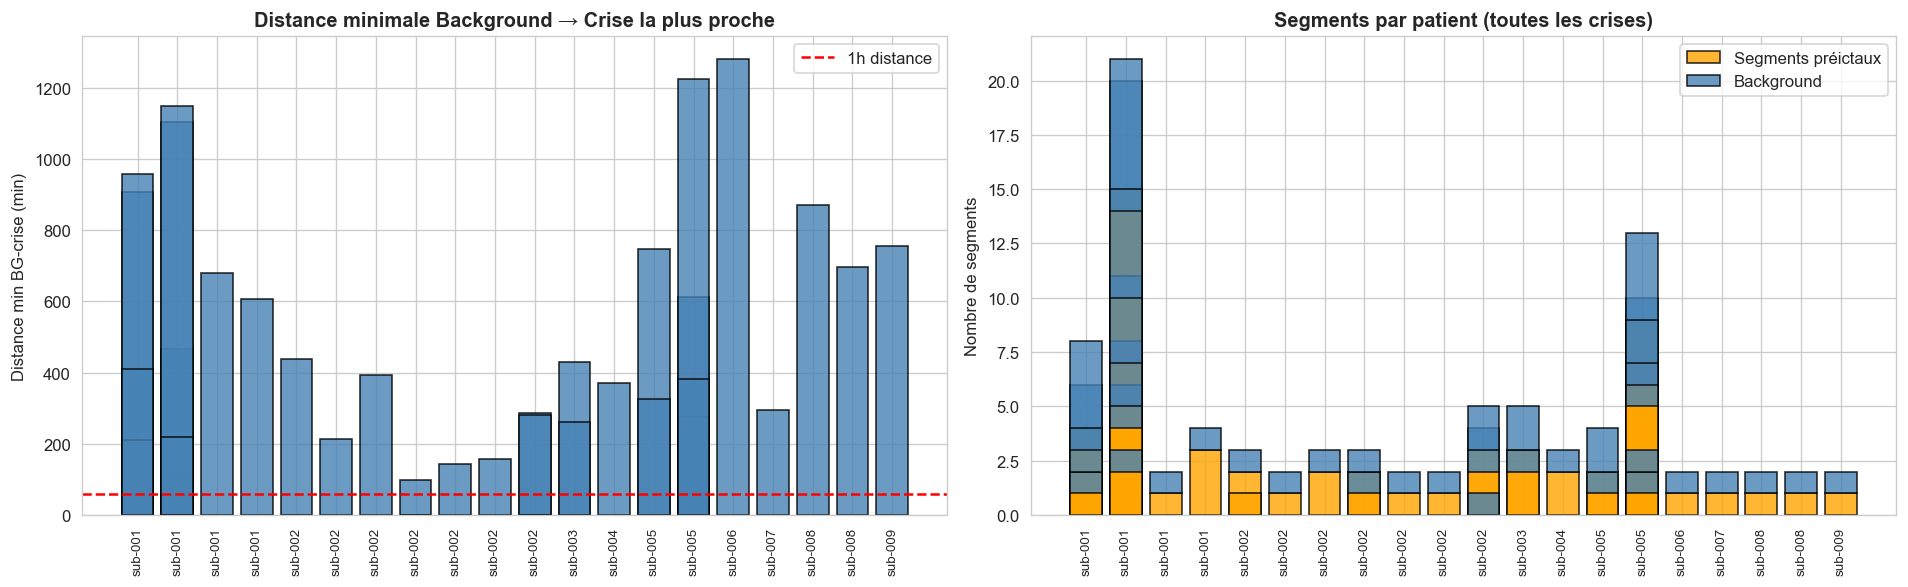

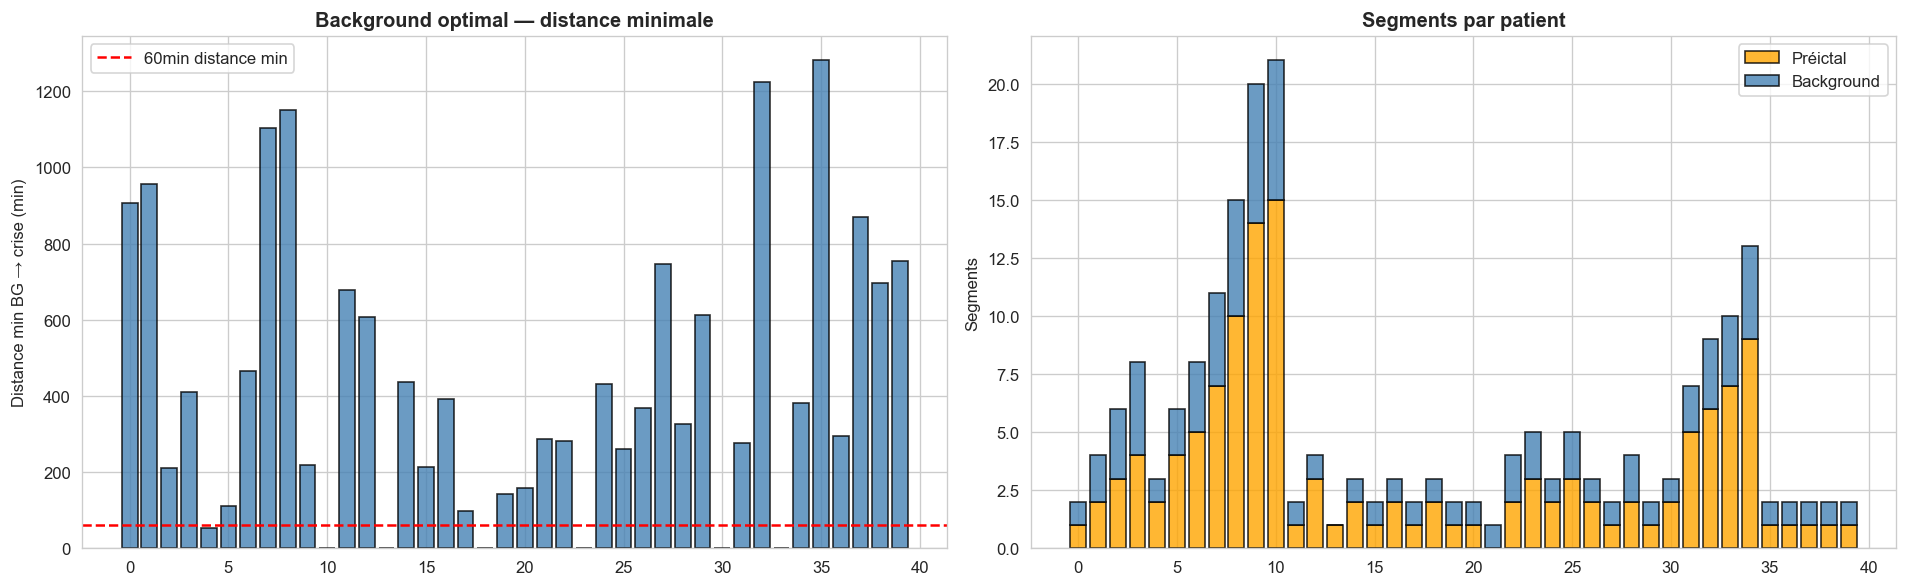

In [9]:
sds=sorted([d for d in DATA_ROOT.iterdir() if d.is_dir() and d.name.startswith('sub-')])
inv={}
for sd in sds:
    f=find_ecg_ev(sd); f and inv.update({sd.name:f})
all_inv=dict(inv)
ps=sorted(inv.keys())[:MAX_PAT]
cpp={pid:sum(len(parse_sz(ev)) for _,ev in inv[pid] if ev) for pid in ps}

# Patient(s) sans crise — parcourir TOUT le dataset
p0=[p for p in sorted(all_inv.keys())
    if sum(len(parse_sz(ev)) for _,ev in all_inv[p] if ev)==0]
p_avec=[p for p in ps if cpp[p]>0]

print(f"{'═'*60}")
print(f"DATASET — {len(ps)} patients")
print(f"{'═'*60}")
for pid in ps:
    print(f"  {pid}: {cpp[pid]} crises")
print(f"  Total : {sum(cpp.values())} crises")
print(f"\n  Patients 0 crise (dataset complet) : {len(p0)} → {p0}")

# ════════════════════════════════════════════════════════════════
# BACKGROUND OPTIMAL — distance maximale avec TOUTES les crises
# ════════════════════════════════════════════════════════════════
def find_best_background(ecg_dur_s, all_seizure_onsets, bg_dur_s=BG_DUR):
    """
    Trouve le segment background le plus éloigné de TOUTES les crises.
    
    Stratégie :
      1. Pour chaque position candidate (toutes les 60s),
         calculer la distance minimale à toutes les crises
      2. Garder la position avec la distance minimale MAXIMALE
      3. Vérifier que le segment tient dans le signal
      
    Retourne : (bg_start_sec, min_distance_sec)
    """
    if not all_seizure_onsets:
        return 0, ecg_dur_s
    
    sz_arr = np.array(all_seizure_onsets)
    best_start = 0
    best_min_dist = 0
    
    # Candidats : toutes les 60 secondes
    candidates = np.arange(0, ecg_dur_s - bg_dur_s, 60)
    
    for c_start in candidates:
        c_mid = c_start + bg_dur_s / 2
        # Distance minimale à toutes les crises depuis le milieu du segment
        dists = np.abs(sz_arr - c_mid)
        min_d = np.min(dists)
        if min_d > best_min_dist:
            best_min_dist = min_d
            best_start = c_start
    
    return float(best_start), float(best_min_dist)

# ════════════════════════════════════════════════════════════════
# SEGMENTATION — TOUTES les crises du patient + Background optimal
# ════════════════════════════════════════════════════════════════
segs=[]
seg_info=[]  # log détaillé

print(f"\n{'═'*70}")
print("SEGMENTATION — Toutes les crises + Background optimal par patient")
print(f"{'═'*70}")

for pid in tqdm(p_avec, desc="Segmentation"):
    pid_segs_pi = 0; pid_segs_bg = 0
    for ep, evp in inv[pid]:
        if evp is None: continue
        szs = parse_sz(evp)
        if not szs: continue
        try: ecg, fs = load_ecg(ep)
        except: continue
        
        ecg_dur = len(ecg) / fs
        all_onsets = [s for s,_ in szs]
        
        # ── Background optimal : segment le plus éloigné de toutes les crises ──
        bg_start, bg_dist = find_best_background(ecg_dur, all_onsets, BG_DUR)
        bg_i0 = int(bg_start * fs)
        bg_i1 = int((bg_start + BG_DUR) * fs)
        
        # Vérifier la qualité du background
        bg_valid = (bg_i1 <= len(ecg) and bg_i0 >= 0)
        
        print(f"  {pid}: {len(szs)} crises | ECG={ecg_dur/3600:.1f}h | "
              f"BG optimal: t={bg_start/60:.0f}min dist_min={bg_dist/60:.0f}min "
              f"{'✓' if bg_valid else '✗'}")
        
        if bg_valid:
            try:
                bc = ecg_filt(ecg[bg_i0:bg_i1], fs)
                # UN SEUL segment background par patient (le meilleur)
                segs.append((pid, "Background", bc, fs, -1))  # seizure_onset=-1 → BG
                pid_segs_bg += 1
            except: pass
        
        # ── Préictal : TOUTES les crises ──
        for s, e in szs:
            pe = s - SPH_S; pst = pe - SOP_S
            if pst < 0: continue
            i0, i1 = int(pst*fs), int(pe*fs)
            if i1 - i0 < int(SOP_S*fs*0.8): continue
            
            try:
                pc = ecg_filt(ecg[i0:i1], fs)
                segs.append((pid, "Pre_Ictal", pc, fs, s))
                pid_segs_pi += 1
            except: pass
        
        seg_info.append({'patient':pid,'n_crises':len(szs),
                         'n_preictal':pid_segs_pi,'n_background':pid_segs_bg,
                         'bg_start_min':round(bg_start/60,1),
                         'bg_dist_min':round(bg_dist/60,1)})

print(f"\nSegments : {len(segs)}")
print(f"  Préictal   : {sum(1 for s in segs if s[1]=='Pre_Ictal')}")
print(f"  Background : {sum(1 for s in segs if s[1]=='Background')} (1 par patient)")

# Extraction features HRV
rows=[]; na,nr=0,0
for pat,ph,eseg,fss,szo in tqdm(segs, desc="HRV features"):
    for w in make_wins(eseg, fss):
        r=get_rp(w,int(fss)); rr=get_rr(r,fss)
        if not qc(r,rr): nr+=1; continue
        ft=hrv(rr)
        if ft is None: nr+=1; continue
        ft["Phase"]=ph; ft["patient"]=pat; ft["seizure_onset"]=szo
        rows.append(ft); na+=1

df=pd.DataFrame(rows); df["label"]=(df["Phase"]=="Pre_Ictal").astype(int)
meta={"Phase","patient","label","seizure_onset"}
afc=[c for c in df.columns if c not in meta]; df[afc]=df[afc].astype(float)

def norm_rob(di,fc):
    do=di.copy()
    for p in do["patient"].unique():
        bg=(do["patient"]==p)&(do["Phase"]=="Background")
        if bg.sum()==0: continue
        med=do.loc[bg,fc].median()
        iqr=(do.loc[bg,fc].quantile(0.75)-do.loc[bg,fc].quantile(0.25)).replace(0,1)
        m=do["patient"]==p; do.loc[m,fc]=(do.loc[m,fc]-med)/iqr
    return do

dfn=norm_rob(df,afc); dfn[afc]=dfn[afc].replace([np.inf,-np.inf],np.nan).fillna(0)
sel=VarianceThreshold(threshold=VAR_THR); sel.fit(dfn[afc])
sf=[f for f,k in zip(afc,sel.get_support()) if k]

print(f"\nAcceptées={na:,} | Rejetées={nr:,} | Features={len(sf)}")
print(f"Pre-ictal={df['label'].sum():,} | Background={(df['label']==0).sum():,}")

# Figure : Background optimal visualisé
df_seg=pd.DataFrame(seg_info)
fig,axes=plt.subplots(1,2,figsize=(16,5))
axes[0].bar(df_seg['patient'],df_seg['bg_dist_min'],color='steelblue',edgecolor='black',alpha=0.8)
axes[0].axhline(60,color='red',ls='--',lw=1.5,label='1h distance')
axes[0].set_xticklabels(df_seg['patient'],rotation=90,fontsize=8)
axes[0].set_ylabel('Distance min BG-crise (min)')
axes[0].set_title('Distance minimale Background → Crise la plus proche',fontweight='bold')
axes[0].legend()
axes[1].bar(df_seg['patient'],df_seg['n_preictal'],color='orange',
            edgecolor='black',alpha=0.8,label='Segments préictaux')
axes[1].bar(df_seg['patient'],df_seg['n_background'],color='steelblue',
            edgecolor='black',alpha=0.8,bottom=df_seg['n_preictal'],label='Background')
axes[1].set_xticklabels(df_seg['patient'],rotation=90,fontsize=8)
axes[1].set_ylabel('Nombre de segments')
axes[1].set_title('Segments par patient (toutes les crises)',fontweight='bold')
axes[1].legend()
plt.tight_layout(); plt.show()

# ── Résumé visuel segmentation ──
if seg_info:
    df_seg = pd.DataFrame(seg_info)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    dists = [s.get('bg_dist_min', 0) for s in seg_info]
    axes[0].bar(range(len(seg_info)), dists, color='steelblue', edgecolor='black', alpha=0.8)
    axes[0].axhline(60, color='red', ls='--', lw=1.5, label='60min distance min')
    axes[0].set_ylabel('Distance min BG → crise (min)')
    axes[0].set_title('Background optimal — distance minimale', fontweight='bold')
    axes[0].legend()
    
    pis = [s.get('n_preictal', 0) for s in seg_info]
    bgs = [s.get('n_background', 0) for s in seg_info]
    x = range(len(seg_info))
    axes[1].bar(x, pis, color='orange', edgecolor='black', alpha=0.8, label='Préictal')
    axes[1].bar(x, bgs, color='steelblue', edgecolor='black', alpha=0.8, bottom=pis, label='Background')
    axes[1].set_ylabel('Segments')
    axes[1].set_title('Segments par patient', fontweight='bold')
    axes[1].legend()
    plt.tight_layout(); plt.show()




---
## Modèle SVM (LOPO)

In [10]:
pl = sorted(dfn["patient"].unique())
p_avec_df = [p for p in pl if p in p_avec]
tvids, tids_base = train_test_split(p_avec_df, test_size=TE_R, random_state=SEED)
vf = VA_R/(TR_R+VA_R)
trids, vids = train_test_split(tvids, test_size=vf, random_state=SEED)

# Patient sans crise — vérifier qu'il n'est pas dans train
P0 = None
for p in p0:
    if p not in trids and p not in vids:
        P0 = p; break

tids  = list(tids_base) + ([P0] if P0 else [])
FEATS = sf
dtr   = dfn[dfn["patient"].isin(trids)]
dva   = dfn[dfn["patient"].isin(vids)]
dte   = dfn[dfn["patient"].isin(tids_base)]  # test sans patient 0-crise pour AUC

# Vérification absence de fuite
assert set(trids).isdisjoint(set(vids)), "FUITE train/val"
assert set(trids).isdisjoint(set(tids_base)), "FUITE train/test"
assert set(vids).isdisjoint(set(tids_base)), "FUITE val/test"

print(f"Train={len(trids)}pts/{len(dtr)}win | Val={len(vids)}pts/{len(dva)}win | Test={len(tids)}pts")
print(f"Test : {sorted(tids)}")
if P0: print(f"✓ {P0} = patient sans crise (test uniquement)")
print("✓ Aucune fuite de données")

def bpipe(k):
    return Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler()),
        ("k",SelectKBest(mutual_info_classif,k=min(k,len(FEATS)))),
        ("svm",SVC(kernel="rbf",class_weight="balanced",probability=True,random_state=SEED))])

PG = {"svm__C":[0.1,1,10], "svm__gamma":["scale",0.001,0.01]}
Xtr=dtr[FEATS].fillna(0); ytr=dtr["label"].values; gtr=dtr["patient"].values
logo = LeaveOneGroupOut()
ba, bm, bk = 0, None, 20
for k in tqdm([15,20,25,30,35,40,41], desc="LOPO"):
    kk = min(k,len(FEATS))
    g = GridSearchCV(bpipe(kk), PG, cv=logo.split(Xtr,ytr,gtr),
                     scoring="roc_auc", n_jobs=-1, refit=True)
    g.fit(Xtr,ytr)
    print(f"  k={kk}: AUC LOPO={g.best_score_:.4f} C={g.best_params_['svm__C']}")
    if g.best_score_ > ba: ba=g.best_score_; bm=g; bk=kk

dtv = pd.concat([dtr,dva]); Xtv=dtv[FEATS].fillna(0); ytv=dtv["label"].values
mdl = bpipe(bk); mdl.set_params(**bm.best_params_); mdl.fit(Xtv,ytv)

# CORRECTION : Seuil Youden sur VAL uniquement (pas train+val)
Xva=dva[FEATS].fillna(0); yva=dva["label"].values
if len(np.unique(yva)) > 1:
    fpr_v,tpr_v,thr_v = roc_curve(yva, mdl.predict_proba(Xva)[:,1])
    THR_GLOBAL = float(np.clip(thr_v[np.argmax(tpr_v-fpr_v)], 0.10, 0.90))
    print(f"\nAUC LOPO={ba:.4f} | Seuil Youden (sur VAL) = {THR_GLOBAL:.4f}")
    THR_GLOBAL_SAVED = float(THR_GLOBAL)
else:
    fpr_c,tpr_c,thr_c = roc_curve(ytv, mdl.predict_proba(Xtv)[:,1])
    THR_GLOBAL = float(np.clip(thr_c[np.argmax(tpr_c-fpr_c)], 0.10, 0.90))
    print(f"\nAUC LOPO={ba:.4f} | Seuil Youden (train+val, fallback) = {THR_GLOBAL:.4f}")
    THR_GLOBAL_SAVED = float(THR_GLOBAL)
    ba_saved = ba  # alias pour synthèse 

    

    



Train=13pts/2328win | Val=2pts/318win | Test=5pts
Test : ['sub-001', 'sub-002', 'sub-006', 'sub-012', 'sub-048']
✓ sub-048 = patient sans crise (test uniquement)
✓ Aucune fuite de données


LOPO:  14%|█▍        | 1/7 [01:42<10:12, 102.07s/it]

  k=15: AUC LOPO=0.7228 C=10


LOPO:  29%|██▊       | 2/7 [02:56<07:09, 85.98s/it] 

  k=20: AUC LOPO=0.7035 C=0.1


LOPO:  43%|████▎     | 3/7 [04:33<06:03, 90.92s/it]

... (6 outputs left out)

  k=40: AUC LOPO=0.7057 C=0.1


LOPO: 100%|██████████| 7/7 [07:32<00:00, 64.66s/it]

  k=41: AUC LOPO=0.7056 C=0.1



AUC LOPO=0.7228 | Seuil Youden (sur VAL) = 0.2625


---
## Calcul des probabilités


In [11]:
# ════════════════════════════════════════════════════════════════
# extract_bg_stats_from_signal — IQR robuste
# ════════════════════════════════════════════════════════════════
def extract_bg_stats_from_signal(ecg, fs, all_seizure_onsets, bg_dur_s=BG_DUR):
    ecg_dur = len(ecg)/fs
    bg_start, _ = find_best_background(ecg_dur, all_seizure_onsets, bg_dur_s)
    bg_i0 = int(bg_start*fs); bg_i1 = int((bg_start+bg_dur_s)*fs)
    if not (0 <= bg_i0 < bg_i1 <= len(ecg)): return None, None
    try: bg_seg = ecg_filt(ecg[bg_i0:bg_i1], fs)
    except: return None, None
    bg_feats = []
    for w in make_wins(bg_seg, fs):
        r=get_rp(w,int(fs)); rr=get_rr(r,fs)
        if not qc(r,rr): continue
        ft=hrv(rr)
        if ft is None: continue
        fv=pd.Series(ft)[FEATS].fillna(0)
        bg_feats.append(fv.values)
    if len(bg_feats) < 10: return None, None
    bg_arr = np.array(bg_feats, dtype=float)
    bmed = pd.Series(np.median(bg_arr,axis=0), index=FEATS)
    q75  = np.percentile(bg_arr,75,axis=0)
    q25  = np.percentile(bg_arr,25,axis=0)
    std_ = np.std(bg_arr,axis=0,ddof=1)
    scale = np.where(q75-q25>1e-8, q75-q25, np.where(std_>1e-8, std_, 1.0))
    biqr  = pd.Series(scale, index=FEATS)
    return bmed, biqr


# ════════════════════════════════════════════════════════════════
# PROBAS SIGNAL COMPLET — Agrégation tous EDF par patient
# ════════════════════════════════════════════════════════════════
pdata = {}
test_pids = list(tids_base) + ([P0] if P0 and P0 in all_inv else [])

for pid in tqdm(test_pids, desc="Probas signal complet"):
    inv_src = all_inv
    if pid not in inv_src: continue
    all_t=[]; all_p=[]; all_sz=[]; dur_total=0

    for ep, evp in inv_src[pid]:
        if evp is None and pid != P0: continue
        szs = parse_sz(evp) if evp else []
        try: ecg, fs = load_ecg(ep)
        except: continue
        all_onsets = [s for s,_ in szs]

        bmed, biqr = extract_bg_stats_from_signal(ecg, fs, all_onsets, BG_DUR)
        if bmed is None:
            bg_m = (dfn["patient"]==pid)&(dfn["Phase"]=="Background")
            if bg_m.sum()>=10:
                bgd=dfn.loc[bg_m,FEATS]; bmed=bgd.median()
                biqr_r=bgd.quantile(0.75)-bgd.quantile(0.25); bstd=bgd.std()
                sc=biqr_r.copy()
                for col in sc.index:
                    if sc[col]<=1e-8: sc[col]=bstd[col] if bstd[col]>1e-8 else 1.0
                biqr=sc
            else:
                bmed=pd.Series(np.zeros(len(FEATS)),index=FEATS)
                biqr=pd.Series(np.ones(len(FEATS)),index=FEATS)

        ef=ecg_filt(ecg,fs); ws=int(WIN_S*fs); st=int((WIN_S-OVL_S)*fs)
        wt,wp=[],[]
        for s in range(0,len(ef)-ws+1,st):
            tc=(s+ws//2)/fs; w=ef[s:s+ws]
            try:
                r=get_rp(w,int(fs)); rr=get_rr(r,fs)
                if not qc(r,rr): wt.append(tc); wp.append(0.0); continue
                ft=hrv(rr)
                if ft is None: wt.append(tc); wp.append(0.0); continue
            except: wt.append(tc); wp.append(0.0); continue
            fv=pd.Series(ft)[FEATS].fillna(0)
            fn=((fv-bmed)/biqr).replace([np.inf,-np.inf],0).fillna(0)
            p=mdl.predict_proba(fn.values.reshape(1,-1))[0,1]
            wt.append(tc); wp.append(float(p))
        all_t.extend(wt); all_p.extend(wp)
        if szs: all_sz.extend(szs)
        dur_total += len(ecg)/fs

    all_t=np.array(all_t); all_p=np.array(all_p)
    if len(all_t)==0: continue

    pct   = (all_p>=THR_GLOBAL).mean()*100
    label = f"{len(all_sz)} crises" if all_sz else "⚠ SANS CRISE"
    print(f"  {pid} | {label} | {len(all_t)} fen | {dur_total/3600:.1f}h | "
          f"moy={all_p.mean():.4f} std={all_p.std():.4f} | "
          f"seuil={THR_GLOBAL:.4f} ({pct:.1f}%>seuil)")

    pdata[pid]={'t':all_t,'p':all_p,'tm':all_t/60,'sz':all_sz,
                'dur':dur_total,'has_sz':bool(all_sz),'dur_h':dur_total/3600}

print(f"\n✓ {len(pdata)} patients | Normalisation BG depuis signal direct")
if P0 in pdata:
    print(f"  ✓ {P0} (sans crise) : {pdata[P0]['dur_h']:.1f}h évalué")

# Diagnostic
print(f"\n{'═'*65}\nDIAGNOSTIC PROBAS\n{'═'*65}")
print(f"{'Patient':<12} {'Moy':>7} {'Std':>7} {'Max':>7} {'Seuil':>8} {'%>seuil':>9}")
print("─"*55)
for pid,d in pdata.items():
    wp=d['p']
    print(f"{pid:<12} {wp.mean():>7.4f} {wp.std():>7.4f} {wp.max():>7.4f} "
          f"{THR_GLOBAL:>8.4f} {(wp>=THR_GLOBAL).mean()*100:>8.1f}%")
if any(d['p'].mean()>0.85 for d in pdata.values()):
    print("\n  ⚠ moy > 0.85 → vérifier la normalisation")
else:
    print("\n  ✓ Probas dans la plage attendue")


Probas signal complet:  20%|██        | 1/5 [03:52<15:28, 232.23s/it]

  sub-001 | 4 crises | 6379 fen | 106.6h | moy=0.5035 std=0.3508 | seuil=0.2625 (60.3%>seuil)


Probas signal complet:  40%|████      | 2/5 [08:19<12:37, 252.55s/it]

  sub-006 | 1 crises | 6558 fen | 109.5h | moy=0.3923 std=0.3040 | seuil=0.2625 (52.2%>seuil)


Probas signal complet:  60%|██████    | 3/5 [13:42<09:30, 285.12s/it]

  sub-012 | 3 crises | 6818 fen | 113.9h | moy=0.4796 std=0.3595 | seuil=0.2625 (55.9%>seuil)


Probas signal complet:  80%|████████  | 4/5 [18:29<04:45, 285.81s/it]

  sub-002 | 15 crises | 5932 fen | 99.2h | moy=0.4174 std=0.3674 | seuil=0.2625 (48.5%>seuil)


Probas signal complet: 100%|██████████| 5/5 [21:35<00:00, 259.18s/it]

  sub-048 | ⚠ SANS CRISE | 4061 fen | 67.8h | moy=0.6598 std=0.3424 | seuil=0.2625 (77.4%>seuil)

✓ 5 patients | Normalisation BG depuis signal direct
  ✓ sub-048 (sans crise) : 67.8h évalué

═════════════════════════════════════════════════════════════════
DIAGNOSTIC PROBAS
═════════════════════════════════════════════════════════════════
Patient          Moy     Std     Max    Seuil   %>seuil
───────────────────────────────────────────────────────
sub-001       0.5035  0.3508  1.0000   0.2625     60.3%
sub-006       0.3923  0.3040  1.0000   0.2625     52.2%
sub-012       0.4796  0.3595  1.0000   0.2625     55.9%
sub-002       0.4174  0.3674  1.0000   0.2625     48.5%
sub-048       0.6598  0.3424  1.0000   0.2625     77.4%

  ✓ Probas dans la plage attendue


---
## Figure — Seuils par patient : distribution + calibration

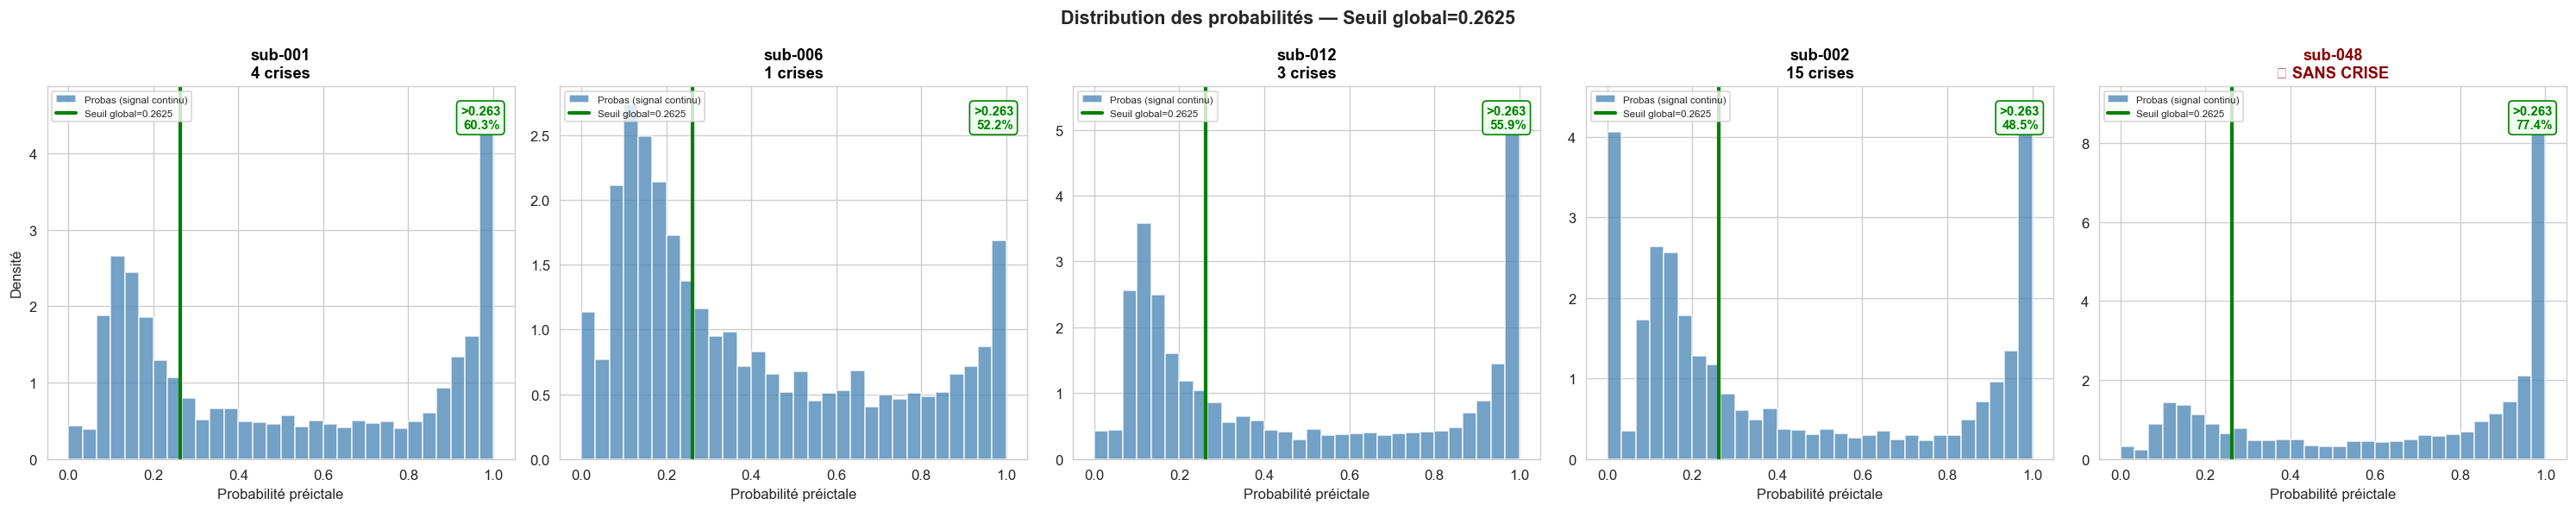

✓ Figure distribution affichée


In [12]:
# ════════════════════════════════════════════════════════════════
# FIGURE : Distribution des probas + seuil global par patient
# ════════════════════════════════════════════════════════════════

n_pats = len(pdata)
fig, axes = plt.subplots(1, n_pats, figsize=(5*n_pats, 5), sharey=False)
if n_pats == 1: axes = [axes]

for idx, (pid, d) in enumerate(pdata.items()):
    ax = axes[idx]
    wp = d['p']
    sz = d.get('sz', [])
    has = len(sz) > 0
    valid = wp
    p_above_g = (wp>=THR_GLOBAL).mean()*100

    ax.hist(valid, bins=30, color='steelblue', alpha=0.75, density=True, label='Probas (signal continu)')
    ax.axvline(THR_GLOBAL, color='green', lw=2.5, ls='-', label=f'Seuil global={THR_GLOBAL:.4f}')

    label = '⚠ SANS CRISE' if not d['has_sz'] else f"{len(d['sz'])} crises"
    ax.set_title(f"{pid}\n{label}",
            fontweight='bold', fontsize=11,
            color='darkred' if not d['has_sz'] else 'black')
    ax.set_xlabel('Probabilité préictale', fontsize=10)
    if idx==0: ax.set_ylabel('Densité', fontsize=10)
    ax.text(0.97, 0.95, f">{THR_GLOBAL:.3f}\n{p_above_g:.1f}%",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            color='green', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', fc='#efffef', ec='green'))
    ax.legend(loc='upper left', fontsize=7)

plt.suptitle(f'Distribution des probabilités — Seuil global={THR_GLOBAL:.4f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print("✓ Figure distribution affichée")


---
## Évaluation temporelle + Alertes par patient

In [13]:
# ════════════════════════════════════════════════════════════════
# eval_patient — cohérence pred/sc + cooldown exact
# ════════════════════════════════════════════════════════════════
def eval_patient(pid, d, thr, nc=N_CONSEC, cd=COOLDOWN):
    """Évalue les alertes d'un patient avec seuil donné.
    - pred = len(sc) — nombre de crises couvertes
    - Une crise ne peut être comptée qu'une seule fois (set sc)
    - Compteur reset explicite après déclenchement
    - Cooldown en secondes (même unité que t)
    """
    t=d['t']; p=d['p']; sz=d['sz']; dur=d['dur']
    preds=(p>=thr).astype(int)
    alerts=[]; la=-np.inf; co=0; vec=[]; log=[]

    for i,(ti,pi,pr) in enumerate(zip(t,p,preds)):
        co = co+1 if pr==1 else 0
        al = False
        if co>=nc and (ti-la)>=cd:
            al=True; alerts.append(ti); la=ti
            cl=co; co=0
        else:
            cl=co
        vec.append(pr)
        log.append({'i':i+1,'t':round(ti/60,2),'p':round(pi,4),'c':pr,'cnt':cl,'al':al})

    szo=[s for s,_ in sz]; sc=set(); at=[]
    for idx,ta in enumerate(alerts):
        vs=ta+SPH_S; ve=ta+SPH_S+SOP_S; m=False; mo=None; dl=None
        for j,s in enumerate(szo):
            if j in sc: continue
            if vs<=s<=ve: m=True; mo=s; dl=s-ta; sc.add(j); break
        at.append({'#':idx+1,'t':round(ta/60,1),'vs':round(vs/60,1),'ve':round(ve/60,1),
                   'cr':round(mo/60,1) if mo else None,'dl':round(dl/60,1) if dl else None,
                   'v':1 if m else 0,'f':0 if m else 1})

    ww=0; au=-np.inf
    for ta in sorted(alerts):
        sw=max(ta,au); ew=ta+SOP_S
        if ew>sw: ww+=ew-sw; au=max(au,ew)

    th=dur/3600; fa=sum(a['f'] for a in at)
    np_=len(sc)

    return ({'pid':pid,'pred':np_,'nsz':len(sz),'fa':fa,'nal':len(alerts),'h':round(th,2),
             'sens':np_/len(sz) if sz else np.nan,
             'fpr_h':fa/th if th>0 else 0,
             'fpr30':fa/(th*2) if th>0 else 0,
             'tiw':min(ww/dur,1.) if dur>0 else 0,
             'has_sz':bool(sz),'thr_used':thr},
            at, np.array(vec), log)


# ─── Évaluation ───
print(f"{'═'*80}")
print(f"ÉVALUATION — Seuil global ({THR_GLOBAL:.4f})")
print(f"PRÉDICTION : alerte → crise attendue dans [alerte+{SPH_S//60}min, alerte+{(SPH_S+SOP_S)//60}min]")
print(f"{'═'*80}")

R_glob=[]; AT_adapt={}; VEC_adapt={}; LOG_adapt={}

for pid, d in pdata.items():
    m_g, at, vec, log = eval_patient(pid, d, THR_GLOBAL)
    R_glob.append(m_g)
    AT_adapt[pid]=at; VEC_adapt[pid]=vec; LOG_adapt[pid]=log

    has=d['has_sz']; sz=d['sz']
    print(f"\n{'═'*75}")
    print(f"PATIENT : {pid} | {'⚠ SANS CRISE' if not has else str(len(sz))+' crises'}")
    print(f"{'═'*75}")

    for a in at:
        if a['v']:
            print(f"  ✅ PRÉDICTION : alerte t={a['t']}min → crise t={a['cr']}min → {a['dl']}min AVANT ✓")

    print(f"\n{'#':>5} {'t(min)':>7} {'Proba':>7} {'Cl':>4} {'Cnt':>5} {'Alerte':>8}")
    print("─"*40)
    for r in log[:25]:
        c="1←" if r['c']==1 else "0 "
        a_s="⚠ALR!" if r['al'] else ""
        cnt=f"→{r['cnt']}←" if r['al'] else str(r['cnt'])
        print(f"{r['i']:>5} {r['t']:>7.1f} {r['p']:>7.4f} {c:>4} {cnt:>5} {a_s:>8}")
    if len(log)>25:
        print(f"  ... {len(log)-25} supplémentaires ...")

    print(f"\n{'─'*72}\nALERTES : {len(at)}")
    if at:
        print(f"{'#':>3} {'t_alerte':>9} {'Fenêtre prédiction':>22} {'Crise':>10} {'Délai':>12} {'Type':>6}")
        print("─"*68)
        for a in at:
            v=f"[{a['vs']}-{a['ve']}min]"
            c=f"{a['cr']}min" if a['cr'] else "—"
            dl=f"{a['dl']}min AVANT" if a['dl'] else "—"
            print(f"{a['#']:>3} {a['t']:>8.1f}min {v:>22} {c:>10} {dl:>12} {'✅' if a['v'] else '❌':>6}")
        nv=sum(a['v'] for a in at); nf=sum(a['f'] for a in at)
        print(f"  Total={len(at)} ✅{nv} ❌{nf}")
        if has: print(f"  Sensitivity={m_g['sens']:.3f} | FPR/h={m_g['fpr_h']:.3f}")
        else:   print(f"  FPR/h={m_g['fpr_h']:.3f}")
    else:
        print("  Aucune alerte")

DF_g = pd.DataFrame(R_glob)
print("\n✓ Évaluation terminée")

# Robustesse par groupe
print(f"\n{'═'*60}\nROBUSTESSE — Métriques par groupe\n{'═'*60}")
for label,df_sub in [("Avec crises",DF_g[DF_g['has_sz']]),("Sans crise",DF_g[~DF_g['has_sz']])]:
    if len(df_sub)==0: continue
    print(f"  {label} (N={len(df_sub)}) :")
    if df_sub['has_sz'].any():
        print(f"    Sensitivity : {df_sub['sens'].mean():.4f} ± {df_sub['sens'].std():.4f}")
    print(f"    FPR/h       : {df_sub['fpr_h'].mean():.4f} ± {df_sub['fpr_h'].std():.4f}")
    print(f"    TiW         : {df_sub['tiw'].mean()*100:.1f}%")
    print(f"    FA total    : {df_sub['fa'].sum()}")


════════════════════════════════════════════════════════════════════════════════
ÉVALUATION — Seuil global (0.2625)
PRÉDICTION : alerte → crise attendue dans [alerte+10min, alerte+40min]
════════════════════════════════════════════════════════════════════════════════

═══════════════════════════════════════════════════════════════════════════
PATIENT : sub-001 | 4 crises
═══════════════════════════════════════════════════════════════════════════
  ✅ PRÉDICTION : alerte t=240.0min → crise t=271.7min → 31.7min AVANT ✓
  ✅ PRÉDICTION : alerte t=458.0min → crise t=471.4min → 13.4min AVANT ✓
  ✅ PRÉDICTION : alerte t=937.0min → crise t=966.2min → 29.2min AVANT ✓
  ✅ PRÉDICTION : alerte t=997.0min → crise t=1016.1min → 19.1min AVANT ✓

    #  t(min)   Proba   Cl   Cnt   Alerte
────────────────────────────────────────
    1     1.0  0.8500   1←     1         
    2     2.0  0.8698   1←     2         
    3     3.0  0.8882   1←   →3←    ⚠ALR!
    4     4.0  0.8732   1←     1         
    5    

---
## Figure — Timeline 3 niveaux par patient

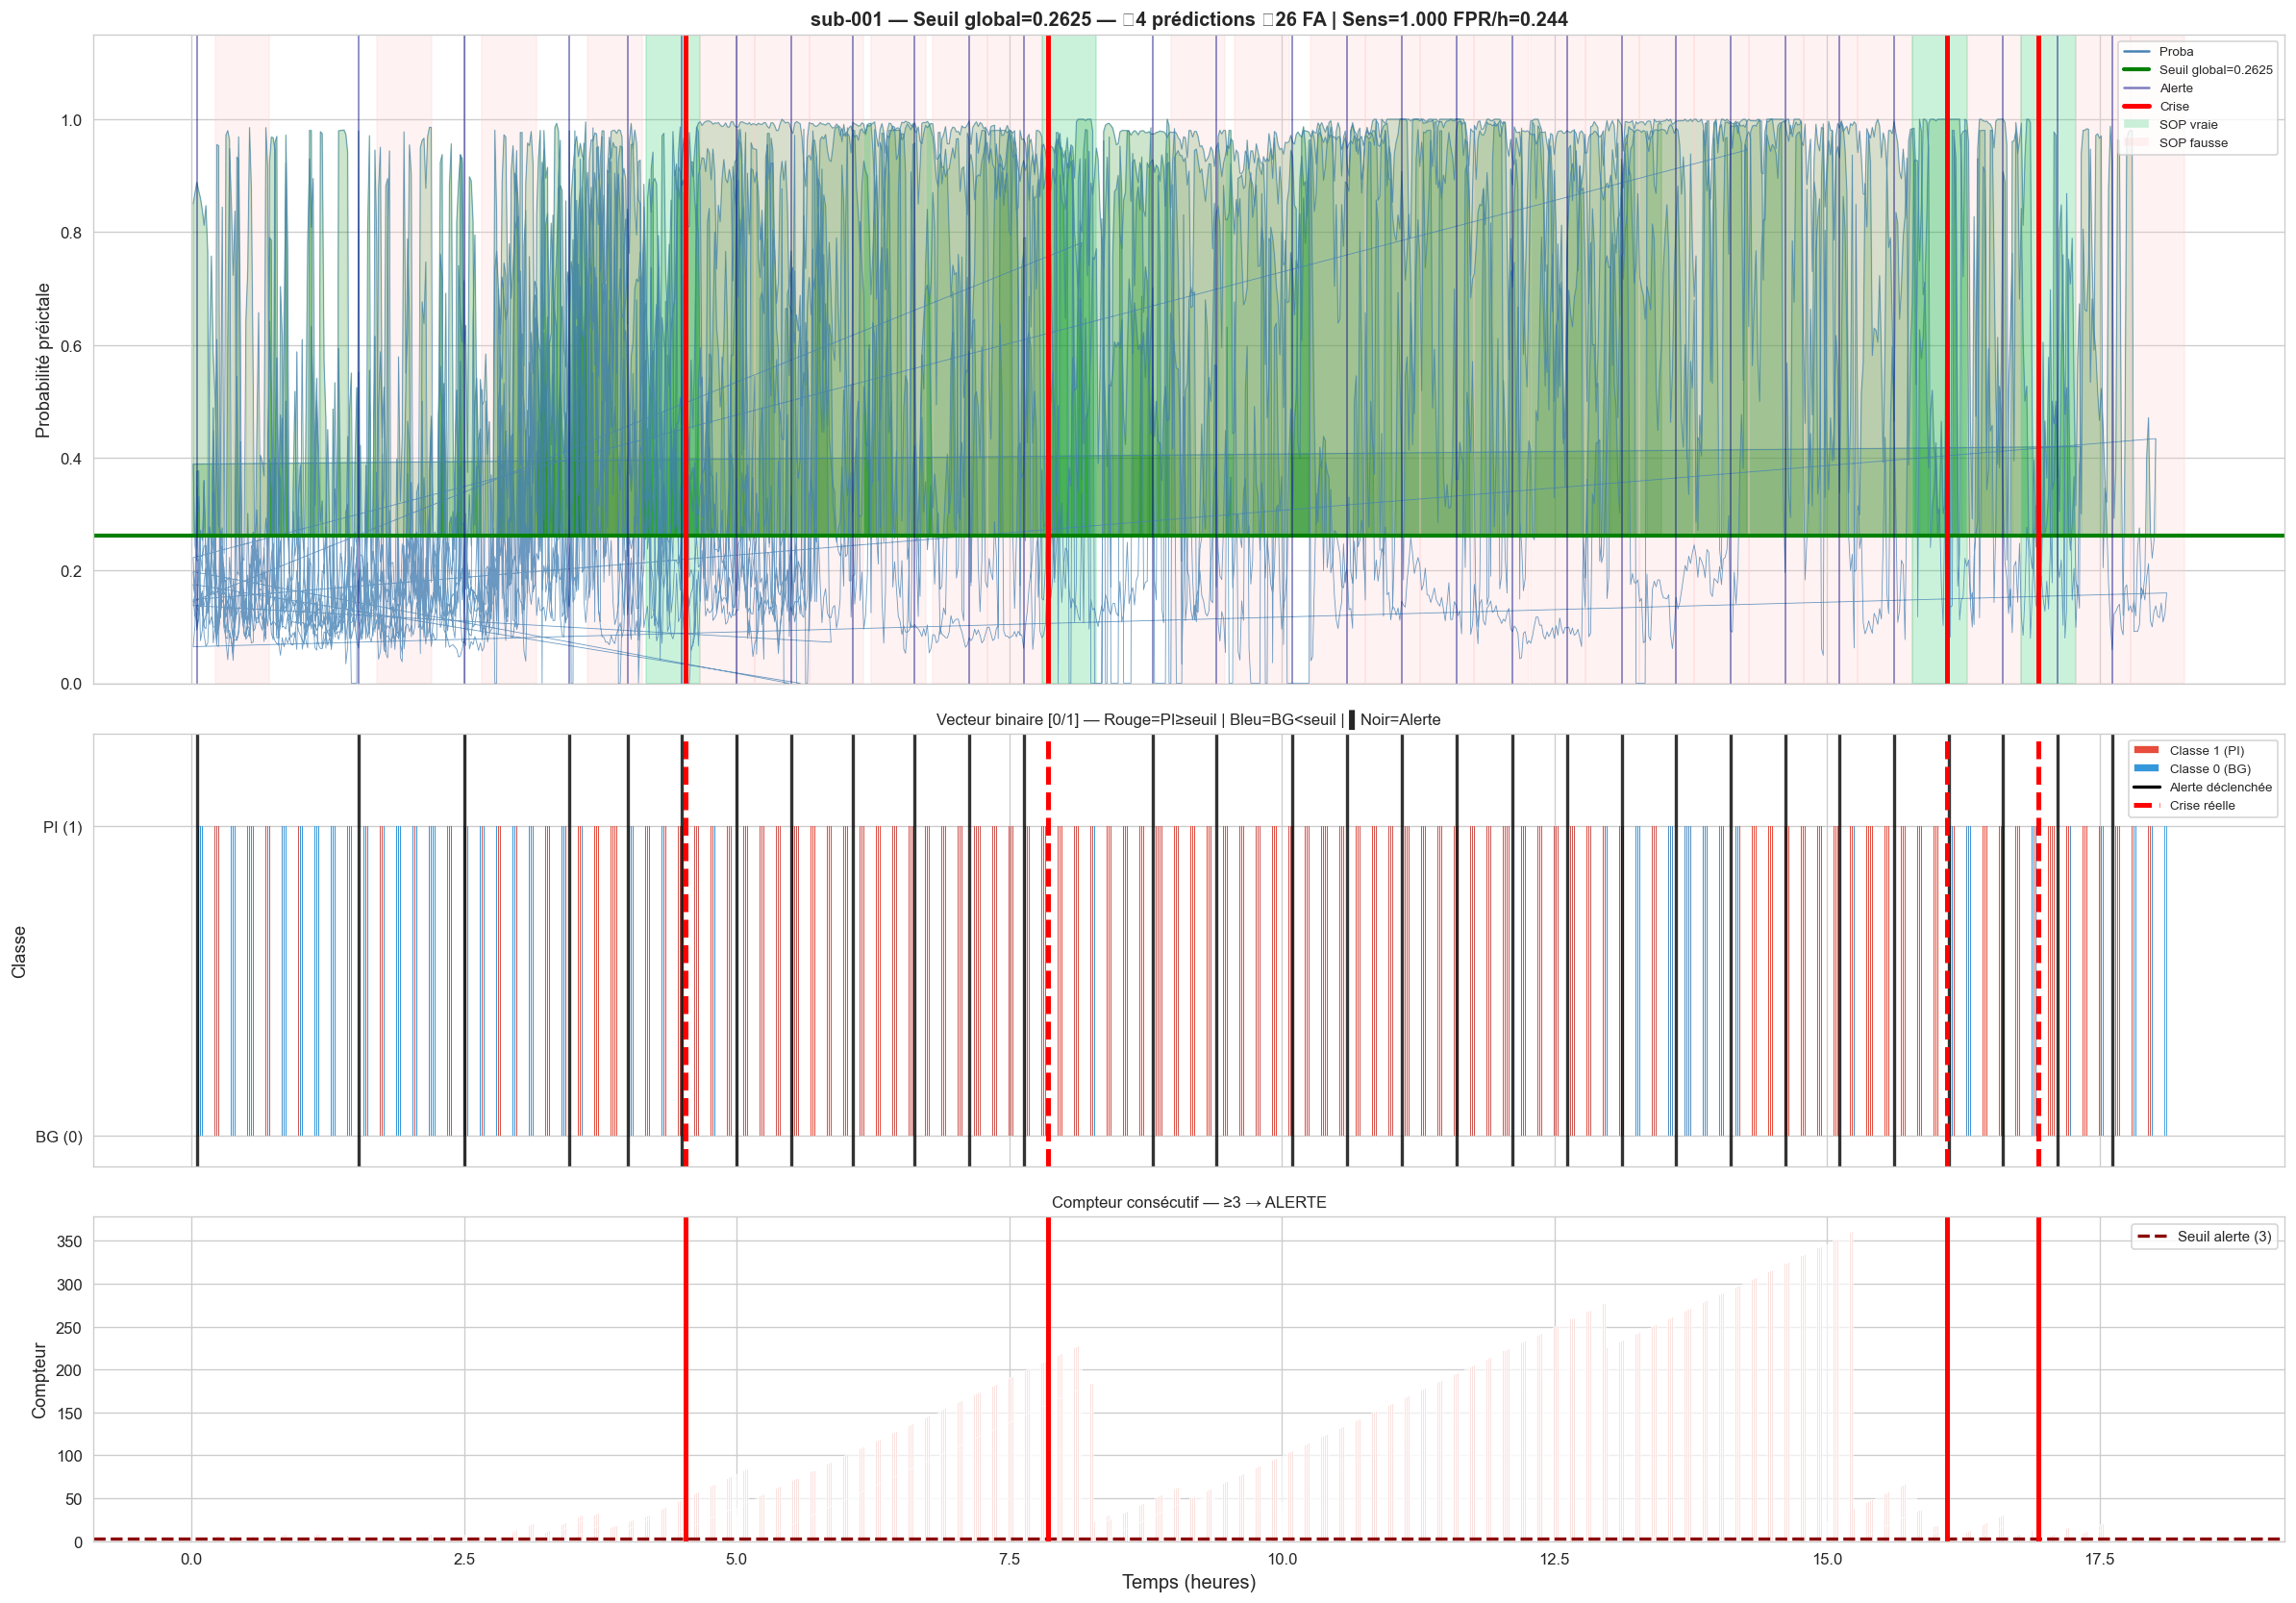

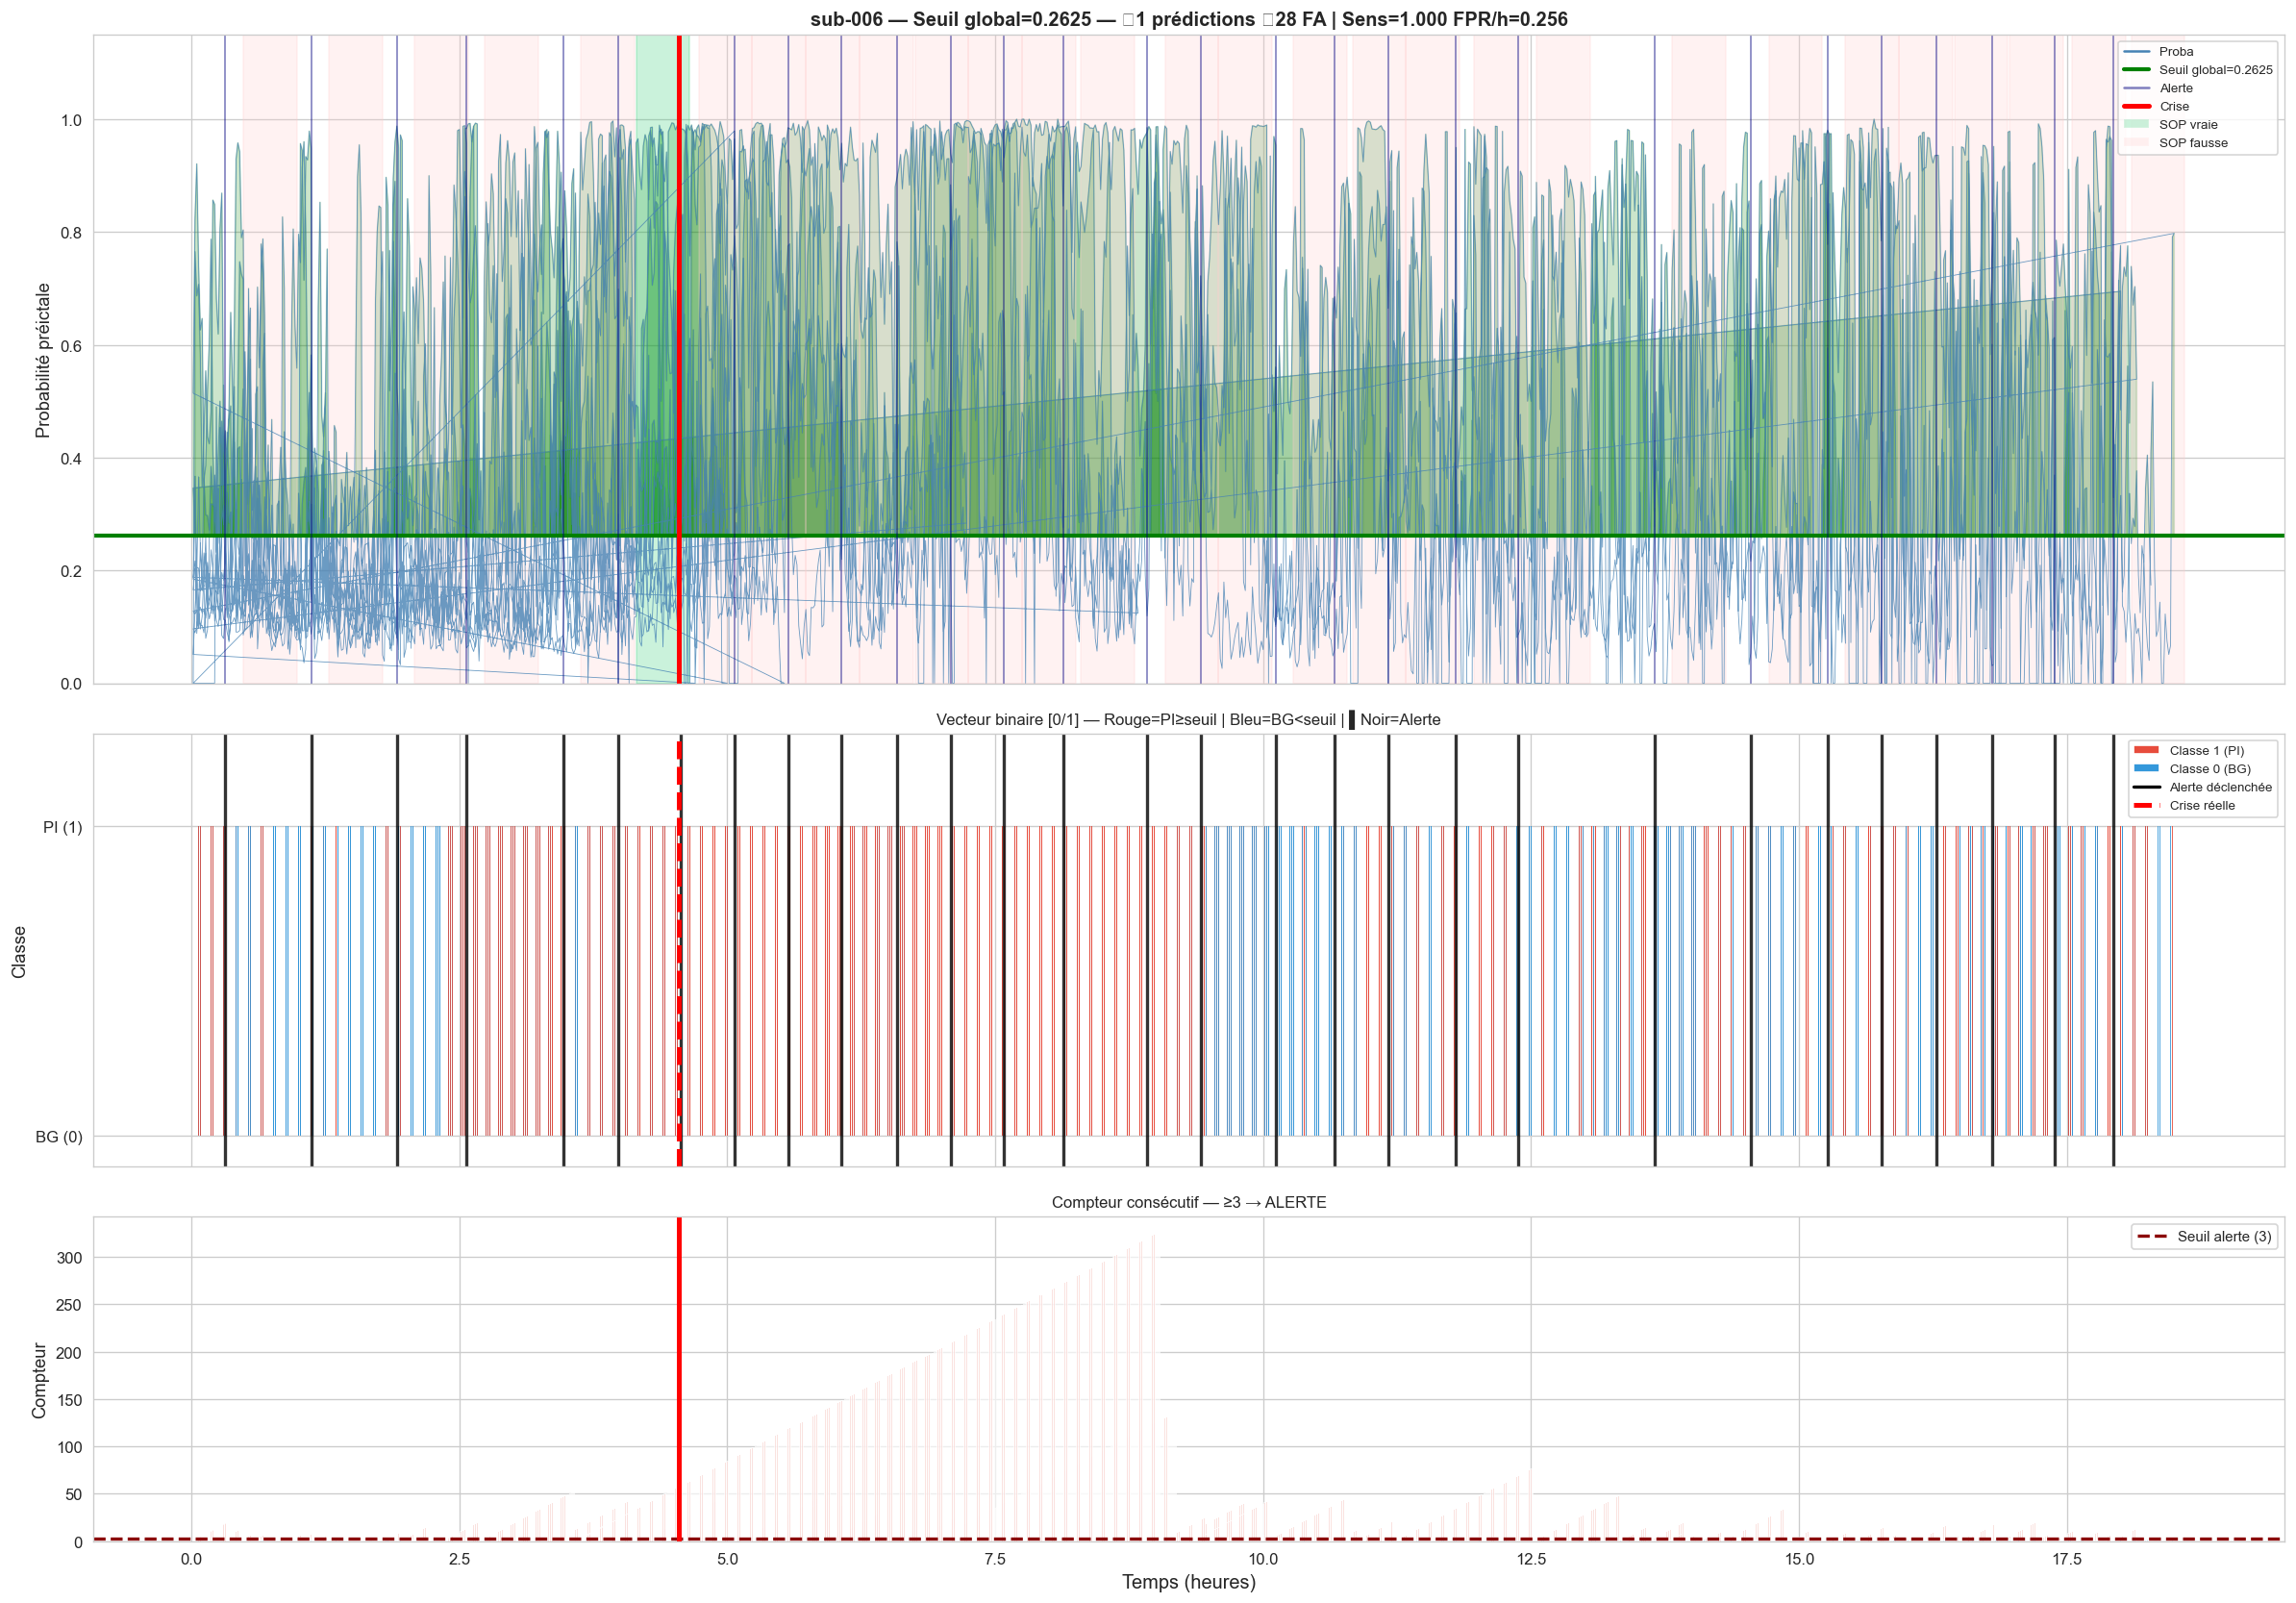

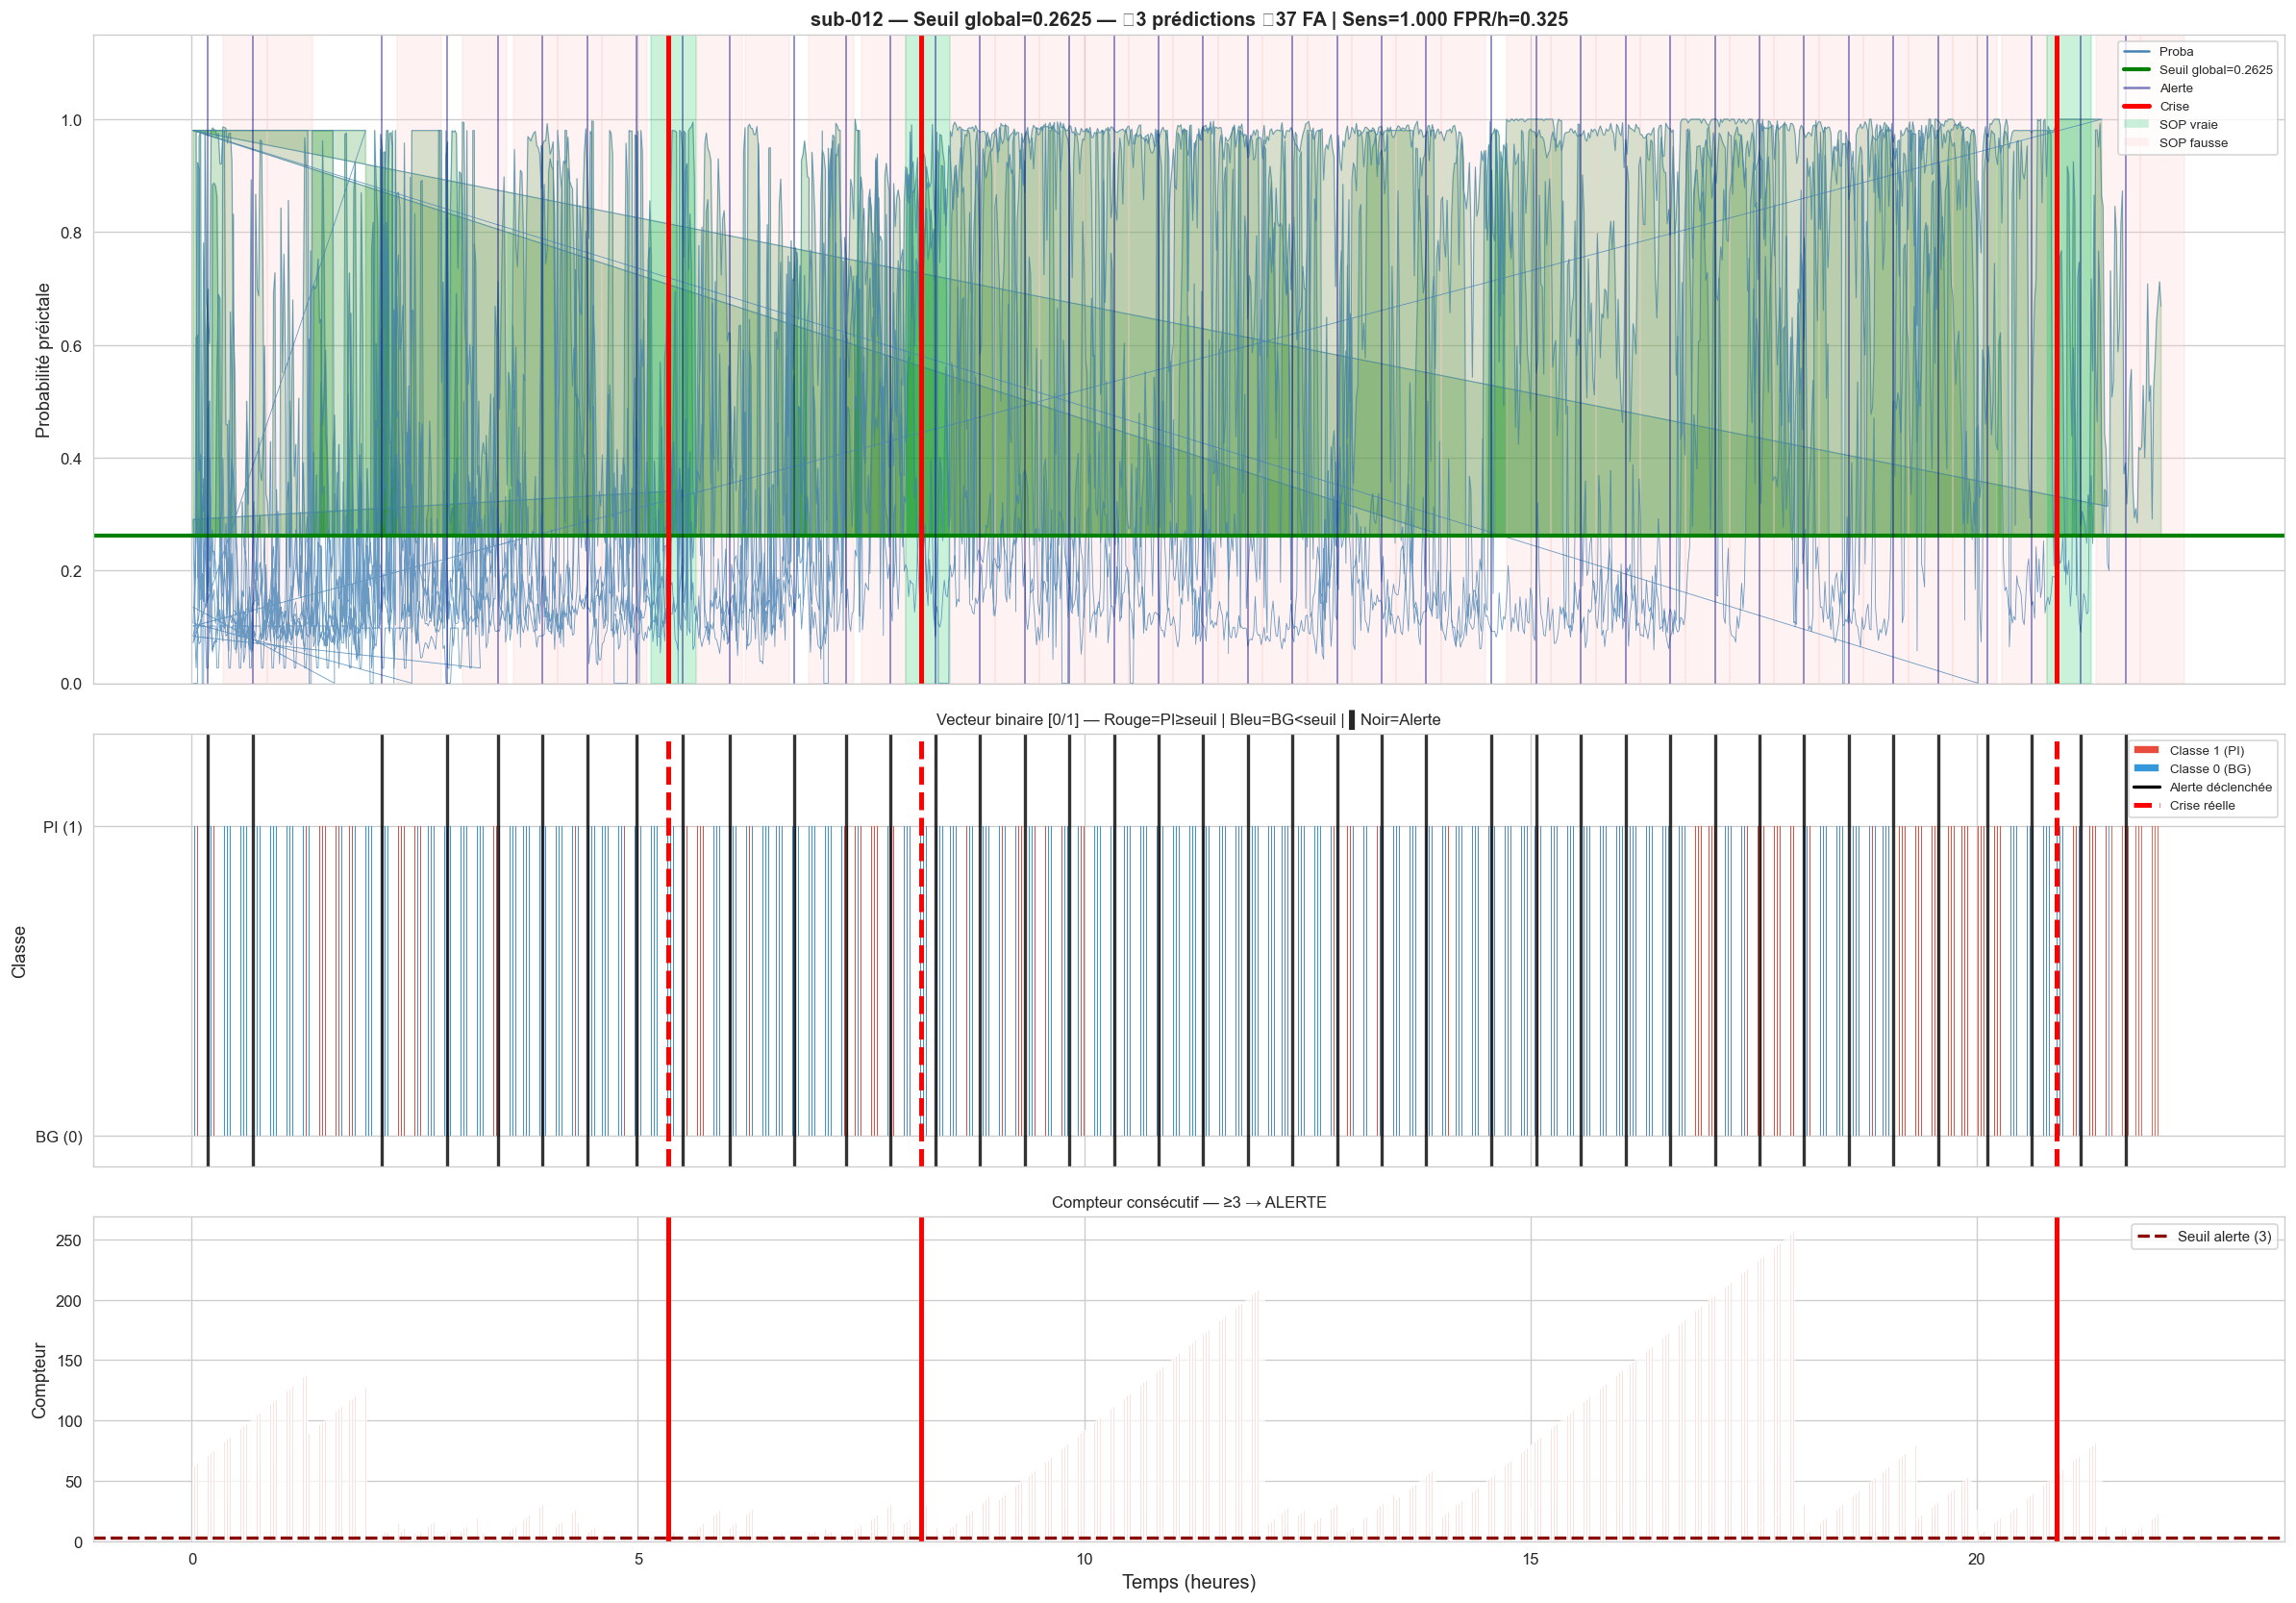

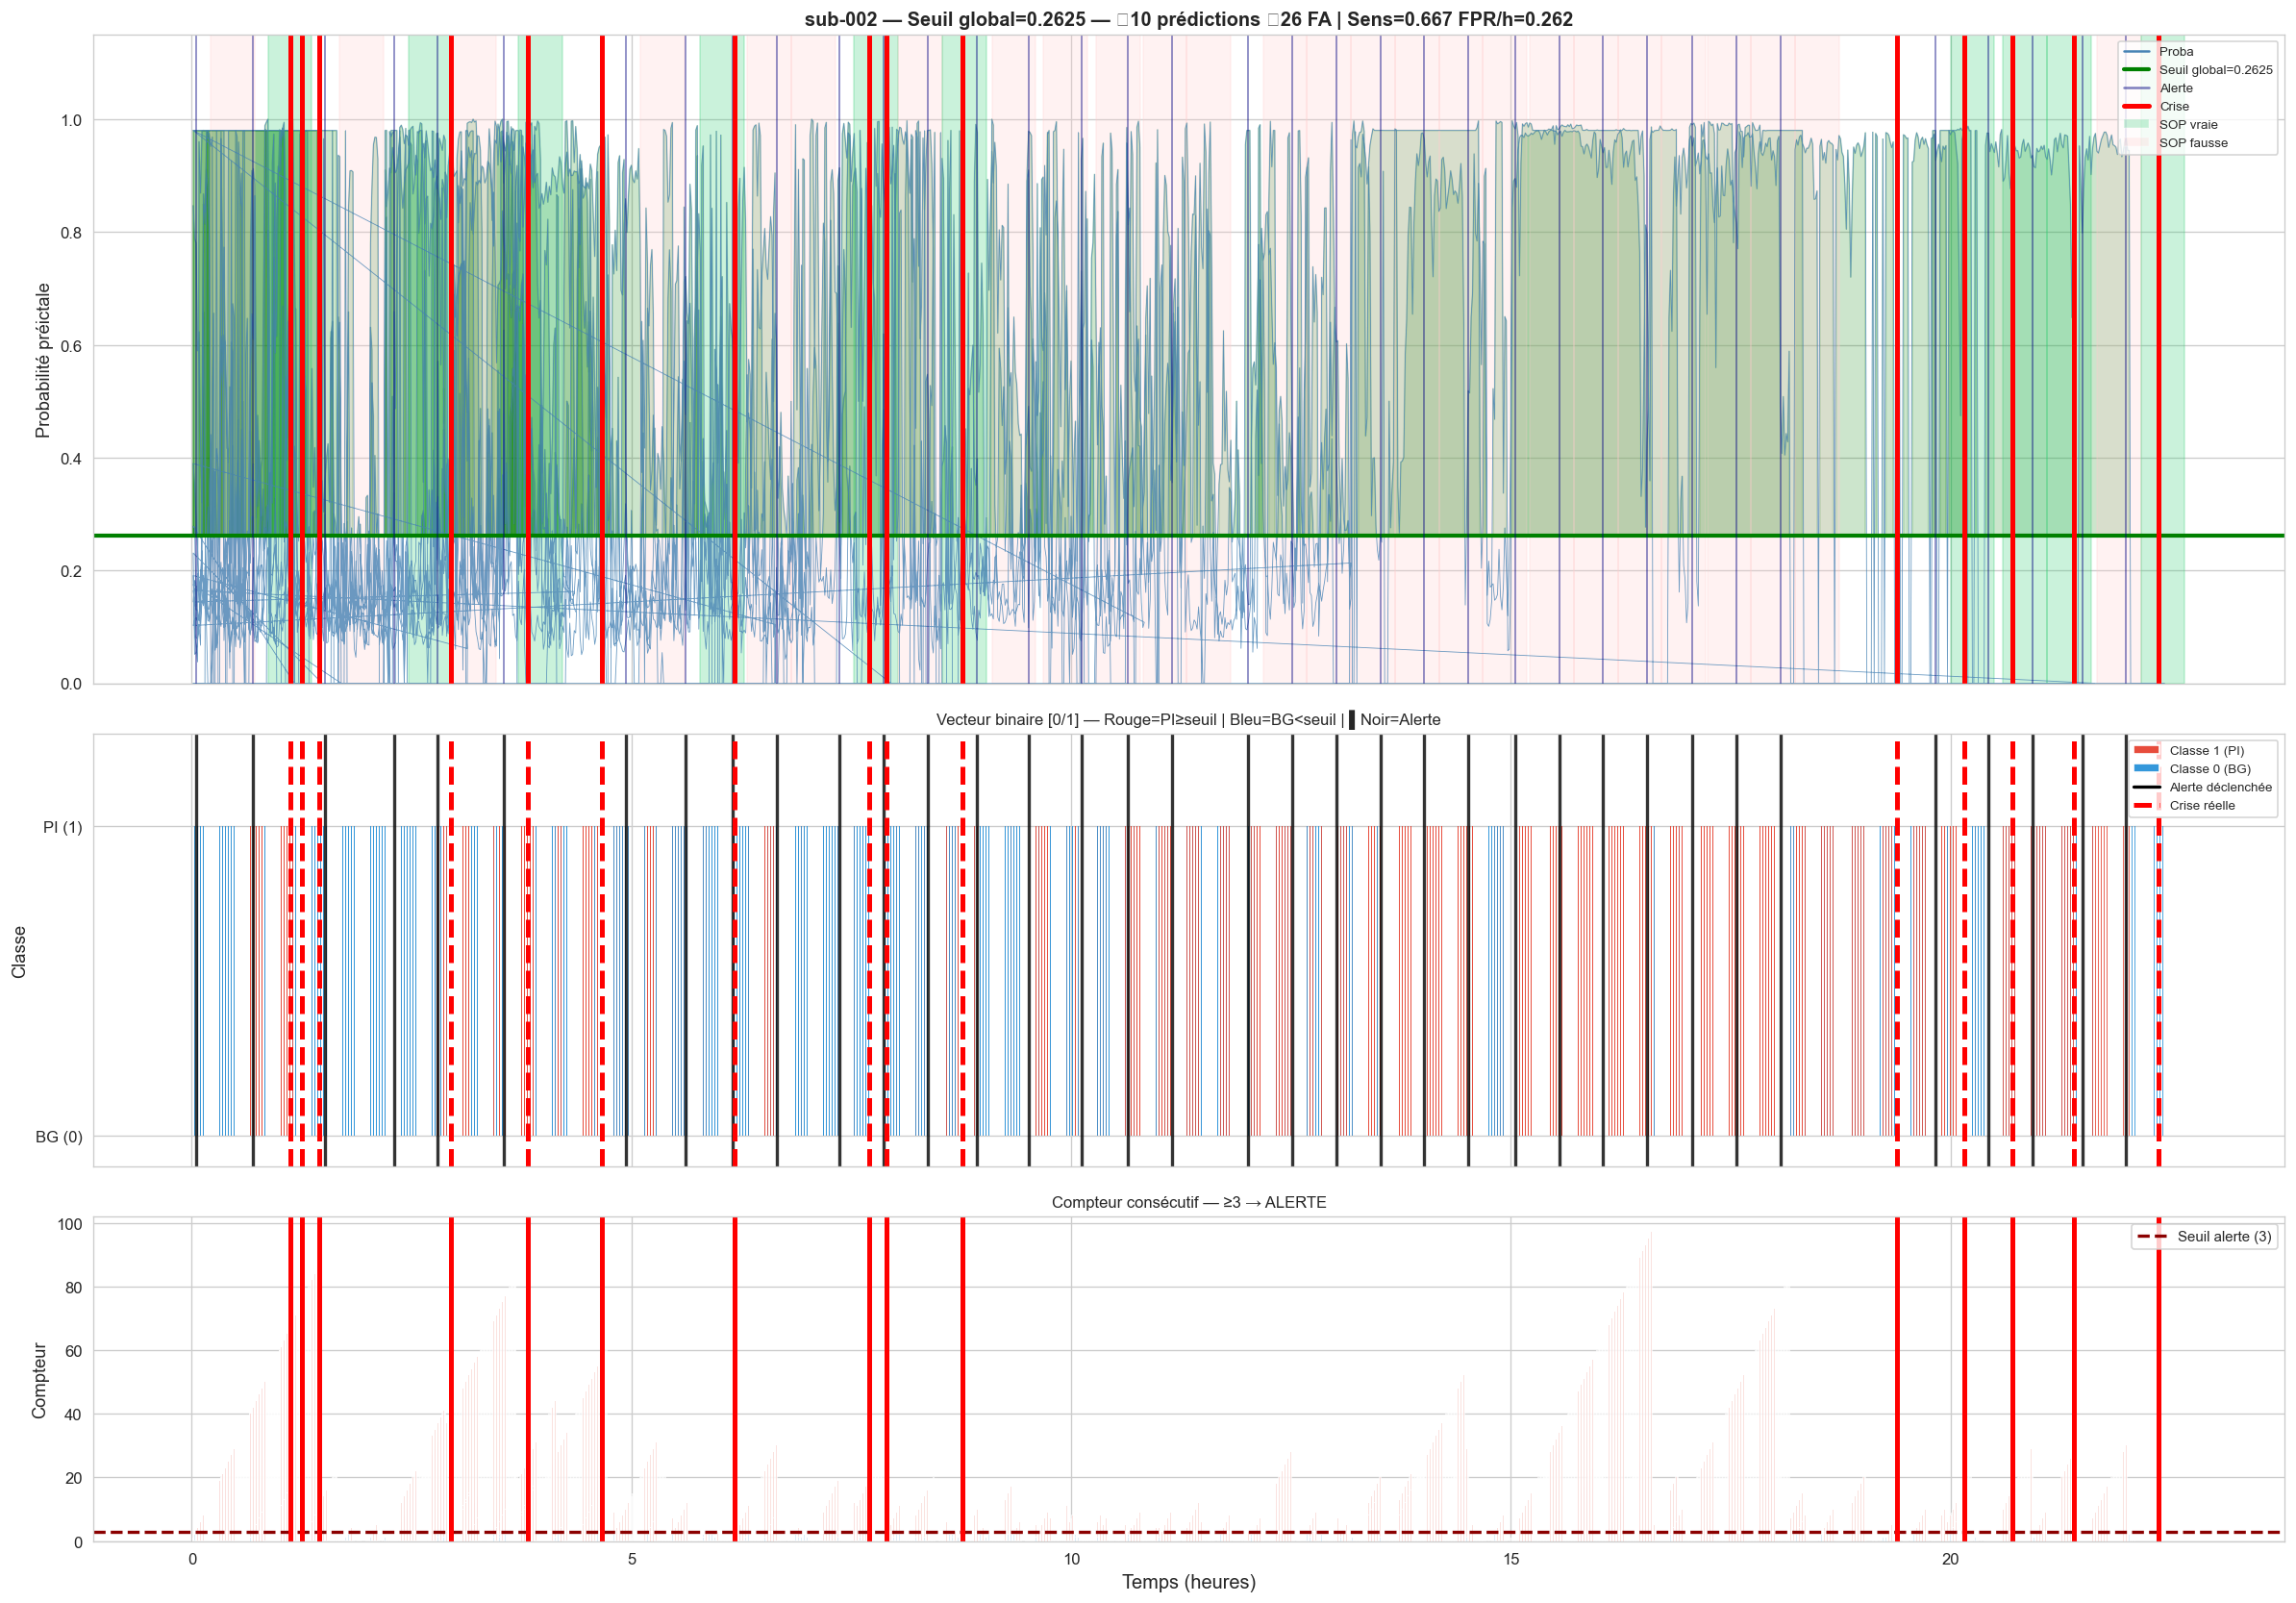

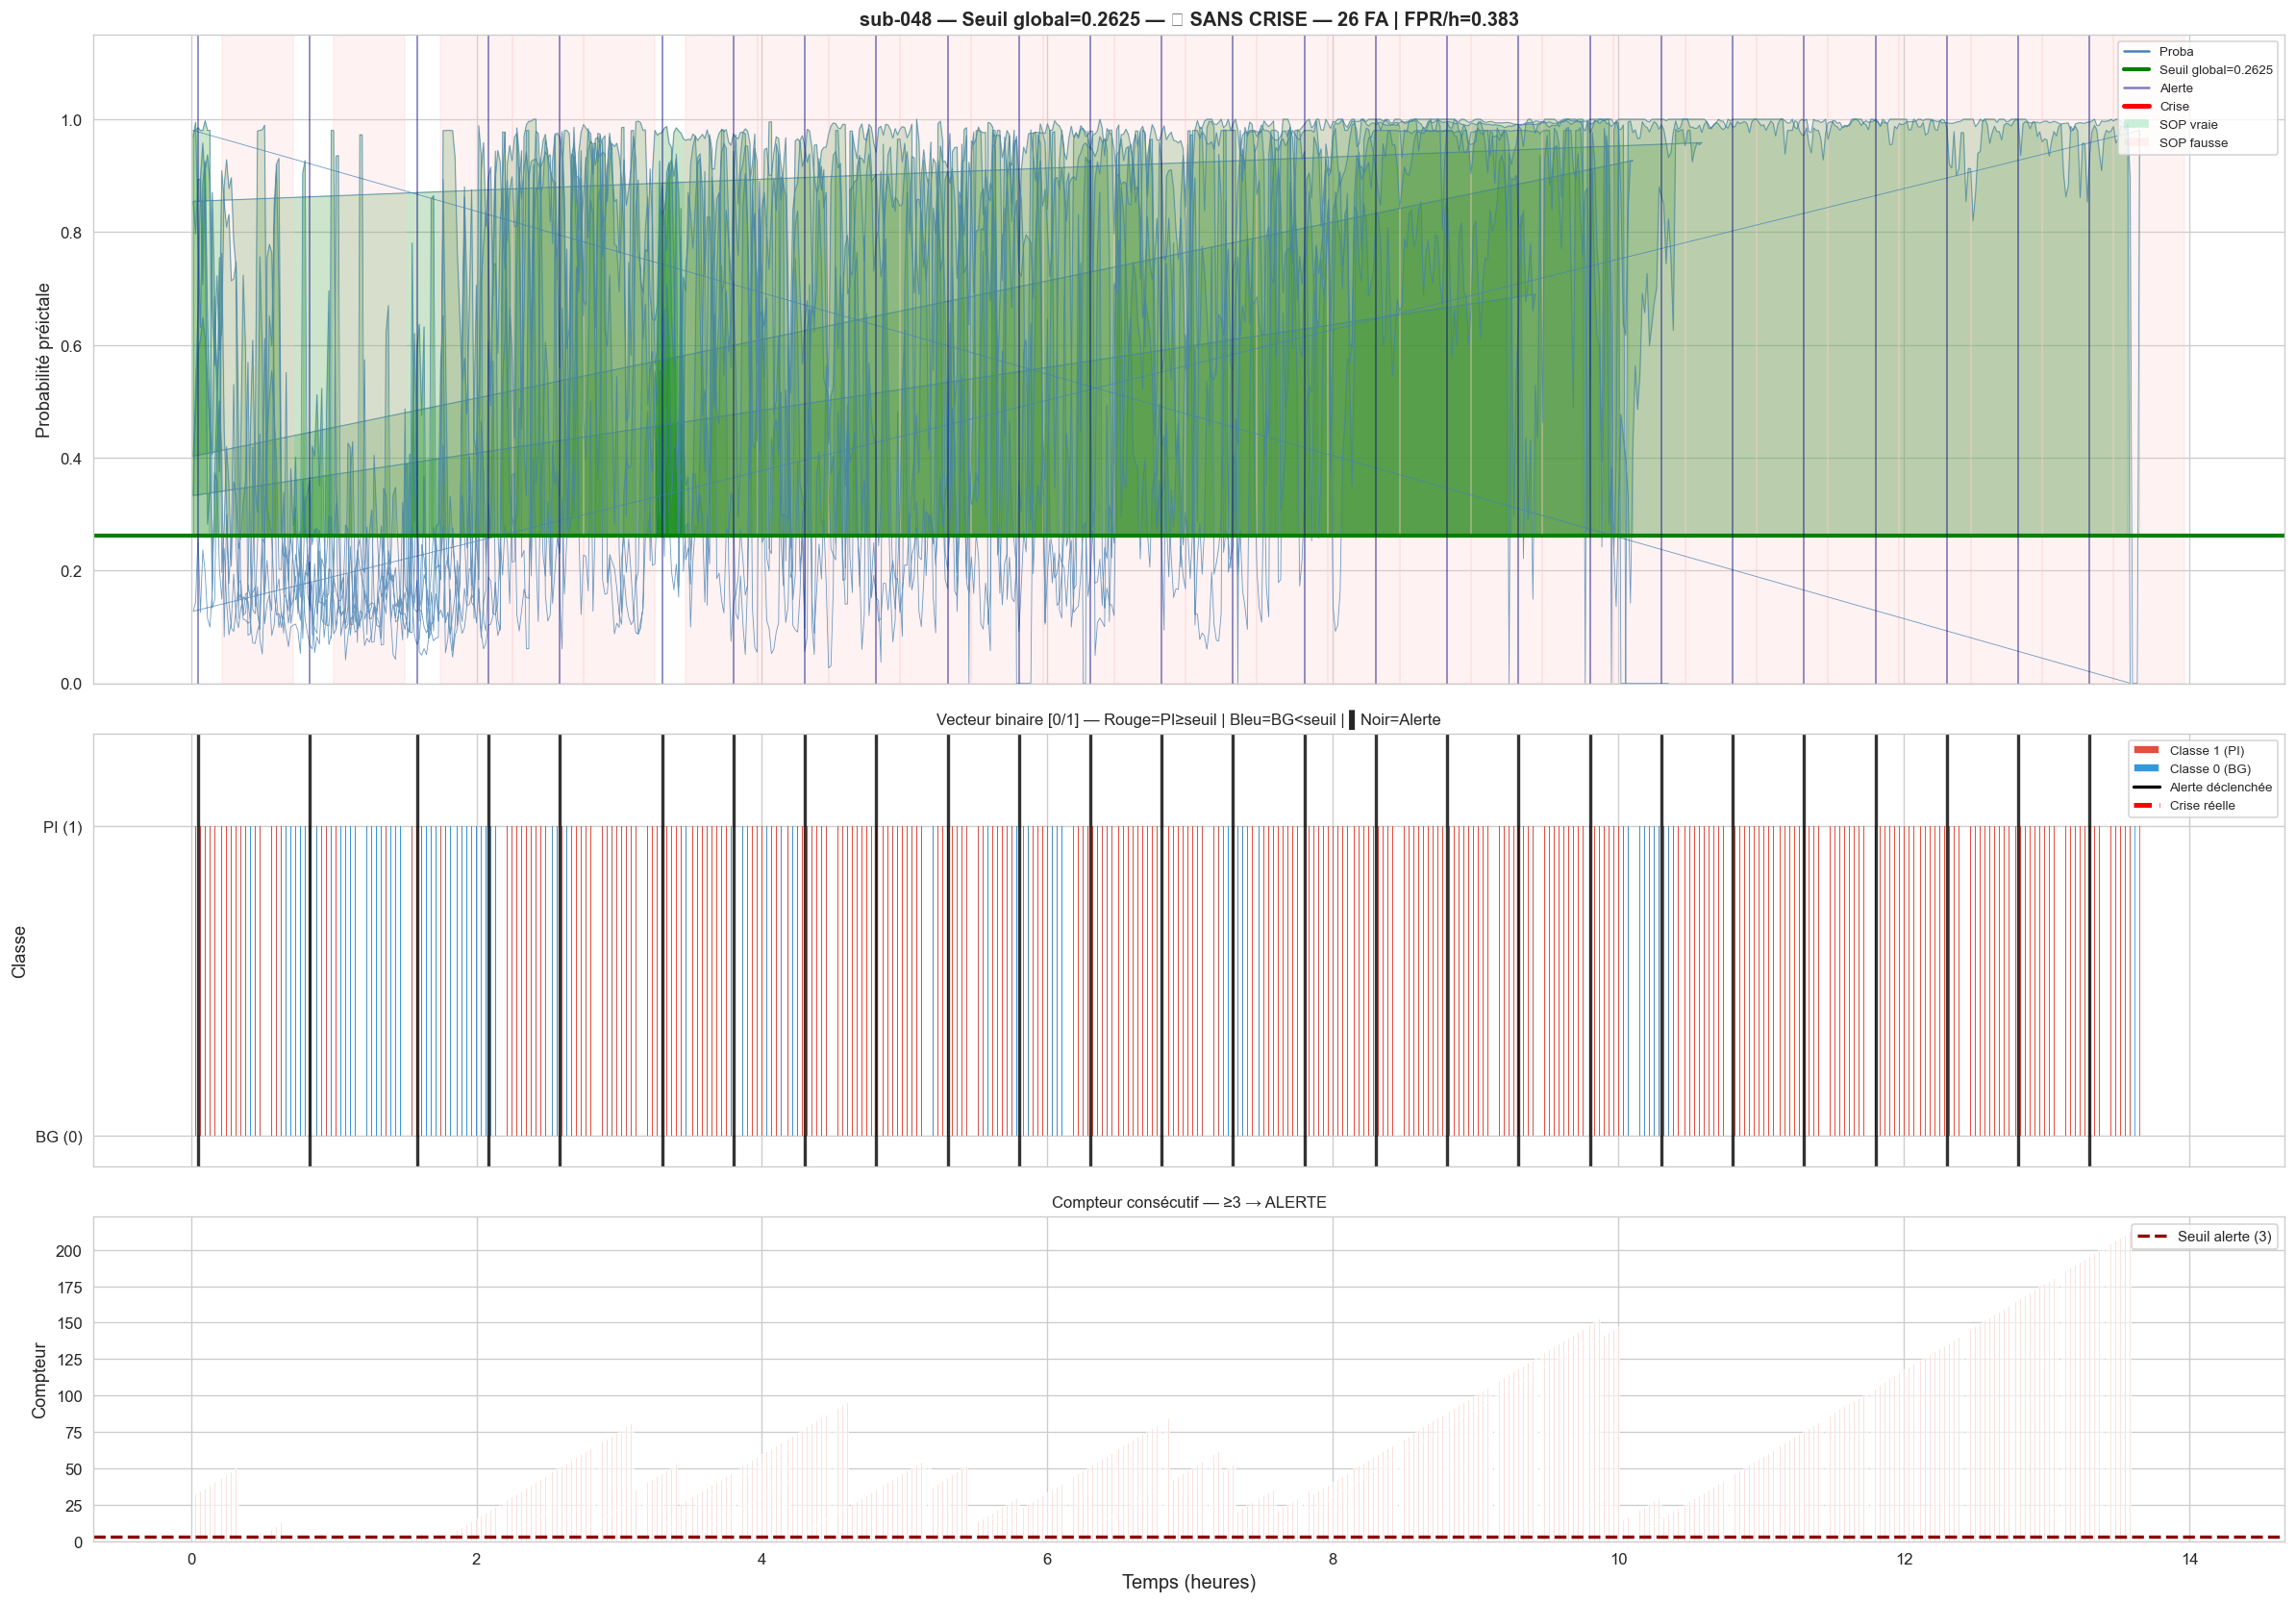

In [14]:
for pid, d in pdata.items():
    at=AT_adapt[pid]; vec=VEC_adapt[pid]; log=LOG_adapt[pid]
    met=DF_g[DF_g['pid']==pid].iloc[0]; has=met['has_sz']
    wt_h=d['t']/3600; wp=d['p']; sz=d['sz']

    fig,axes=plt.subplots(3,1,figsize=(20,14),sharex=True,
                           gridspec_kw={'height_ratios':[3,2,1.5]})

    # ── 1. Probabilité ──
    axes[0].plot(wt_h,wp,lw=0.5,color='steelblue',alpha=0.8)
    axes[0].axhline(THR_GLOBAL,color='green',lw=2.5,ls='-',label=f'Seuil global={THR_GLOBAL:.4f}')
    axes[0].fill_between(wt_h,wp,THR_GLOBAL,where=(wp>=THR_GLOBAL),alpha=0.2,color='green')
    for a in at:
        c='#2ecc71' if a['v'] else '#ffcccc'
        axes[0].axvspan(a['vs']/60,a['ve']/60,alpha=0.25,color=c)
        axes[0].axvline(a['t']/60,color='navy',lw=1,alpha=0.5)
    for ss,_ in sz: axes[0].axvline(ss/3600,color='red',lw=3)
    axes[0].set_ylim([0,max(0.6,max(wp)*1.15)])
    axes[0].set_ylabel('Probabilité préictale',fontsize=11)
    nv=sum(a['v'] for a in at); nf=sum(a['f'] for a in at)
    title=f"{pid} — Seuil global={THR_GLOBAL:.4f}"
    if has: title+=f" — ✅{nv} prédictions ❌{nf} FA | Sens={met['sens']:.3f} FPR/h={met['fpr_h']:.3f}"
    else:   title+=f" — ⚠ SANS CRISE — {nf} FA | FPR/h={met['fpr_h']:.3f}"
    axes[0].set_title(title,fontweight='bold',fontsize=12)
    axes[0].legend(handles=[
        Line2D([0],[0],color='steelblue',label='Proba'),
        Line2D([0],[0],color='green',lw=2.5,label=f'Seuil global={THR_GLOBAL:.4f}'),
        Line2D([0],[0],color='navy',alpha=0.5,label='Alerte'),
        Line2D([0],[0],color='red',lw=3,label='Crise'),
        Patch(facecolor='#2ecc71',alpha=0.25,label='SOP vraie'),
        Patch(facecolor='#ffcccc',alpha=0.25,label='SOP fausse'),
    ],loc='upper right',fontsize=8)

    # ── 2. Vecteur binaire [0,1] ──
    n=min(len(vec),len(wt_h))
    for k in range(n):
        axes[1].bar(wt_h[k],1,width=0.003,
                    color='#e74c3c' if vec[k]==1 else '#3498db',linewidth=0,alpha=0.85)
    for a in at: axes[1].axvline(a['t']/60,color='black',lw=2,alpha=0.8)
    for ss,_ in sz: axes[1].axvline(ss/3600,color='red',lw=3,ls='--')
    axes[1].set_ylim([-0.1,1.3]); axes[1].set_yticks([0,1])
    axes[1].set_yticklabels(['BG (0)','PI (1)'],fontsize=10)
    axes[1].set_ylabel('Classe',fontsize=11)
    axes[1].set_title('Vecteur binaire [0/1] — Rouge=PI≥seuil | Bleu=BG<seuil | ▌Noir=Alerte',fontsize=10)
    axes[1].legend(handles=[
        Patch(facecolor='#e74c3c',label='Classe 1 (PI)'),
        Patch(facecolor='#3498db',label='Classe 0 (BG)'),
        Line2D([0],[0],color='black',lw=2,label='Alerte déclenchée'),
        Line2D([0],[0],color='red',lw=3,ls='--',label='Crise réelle'),
    ],loc='upper right',fontsize=8)

    # ── 3. Compteur consécutif ──
    cnts=[r['cnt'] for r in log[:n]]; n_c=min(len(cnts),len(wt_h))
    axes[2].bar(wt_h[:n_c],cnts[:n_c],width=0.003,
                color=['#e74c3c' if c>=N_CONSEC else '#3498db' for c in cnts[:n_c]],alpha=0.8)
    axes[2].axhline(N_CONSEC,color='darkred',ls='--',lw=2,label=f'Seuil alerte ({N_CONSEC})')
    for ss,_ in sz: axes[2].axvline(ss/3600,color='red',lw=3)
    axes[2].set_ylabel('Compteur',fontsize=11); axes[2].set_xlabel('Temps (heures)',fontsize=12)
    axes[2].set_title(f'Compteur consécutif — ≥{N_CONSEC} → ALERTE',fontsize=10)
    axes[2].legend(loc='upper right',fontsize=9)

    plt.tight_layout(); plt.show()


---
## Résultats finaux


In [15]:
df_sz = DF_g[DF_g['has_sz']==True]
df_0  = DF_g[DF_g['has_sz']==False]

print(f"{'═'*60}")
print(f"RÉSULTATS — Seuil global ({THR_GLOBAL:.4f})")
print(f"{'═'*60}")
print(f"\n{'Patient':<10} {'Sens':>6} {'FPR/h':>7} {'TiW%':>7} {'FA':>4}")
print("─"*35)
for pid in pdata:
    g = DF_g[DF_g['pid']==pid].iloc[0]
    has = pdata[pid]['has_sz']
    gs = f"{g['sens']:.3f}" if has else "N/A"
    print(f"{pid:<10} {gs:>6} {g['fpr_h']:>7.3f} {g['tiw']*100:>6.1f}% {g['fa']:>4}")

print(f"\n  MOYENNE (patients avec crises) :")
print(f"  Sensitivity={df_sz['sens'].mean():.4f} | FPR/h={df_sz['fpr_h'].mean():.4f} | TiW={df_sz['tiw'].mean()*100:.1f}% | FA={df_sz['fa'].sum()}")
if len(df_0)>0:
    print(f"\n  PATIENTS SANS CRISE :")
    for _,r in df_0.iterrows():
        print(f"  {r['pid']}: {r['fa']} FA | FPR/h={r['fpr_h']:.3f}")


════════════════════════════════════════════════════════════
RÉSULTATS — Seuil global (0.2625)
════════════════════════════════════════════════════════════

Patient      Sens   FPR/h    TiW%   FA
───────────────────────────────────
sub-001     1.000   0.244   14.1%   26
sub-006     1.000   0.256   13.2%   28
sub-012     1.000   0.325   17.6%   37
sub-002     0.667   0.262   18.1%   26
sub-048       N/A   0.383   19.2%   26

  MOYENNE (patients avec crises) :
  Sensitivity=0.9167 | FPR/h=0.2716 | TiW=15.8% | FA=117

  PATIENTS SANS CRISE :
  sub-048: 26 FA | FPR/h=0.383


In [16]:
import joblib, json
import numpy as np

# ── Sauvegarde du modèle SVM ──
joblib.dump(mdl, "svm_epilepsie.pkl")
print("✓ Modèle sauvegardé : svm_epilepsie.pkl")

# ── Sauvegarde des paramètres nécessaires ──
params = {
    "THR_GLOBAL"   : float(THR_GLOBAL),
    "FEATS"        : list(FEATS),         # noms des features sélectionnées
    "WIN_S"        : WIN_S,
    "OVL_S"        : OVL_S,
    "SPH_S"        : SPH_S,
    "SOP_S"        : SOP_S,
    "N_CONSEC"     : N_CONSEC,
    "COOLDOWN"     : COOLDOWN,
    "FS"           : 250,
}
with open("params_epilepsie.json", "w") as f:
    json.dump(params, f, indent=2)
print("✓ Paramètres sauvegardés : params_epilepsie.json")

# ── Sauvegarde des stats background par patient ──
# (nécessaires pour la normalisation en temps réel)
bg_stats = {}
for pid in tqdm(pdata.keys(), desc="Export BG stats"):
    d    = pdata[pid]
    mask = (dfn["patient"] == pid) & (dfn["Phase"] == "Background")
    if mask.sum() == 0:
        continue
    bg_data = dfn.loc[mask, FEATS]
    med  = bg_data.median().to_dict()
    q75  = bg_data.quantile(0.75)
    q25  = bg_data.quantile(0.25)
    iqr  = (q75 - q25)
    std_ = bg_data.std()
    scale = iqr.copy()
    for col in scale.index:
        if scale[col] <= 1e-8:
            scale[col] = std_[col] if std_[col] > 1e-8 else 1.0
    bg_stats[pid] = {
        "median" : med,
        "iqr"    : scale.to_dict(),
    }

with open("bg_stats_epilepsie.json", "w") as f:
    json.dump(bg_stats, f, indent=2)
print(f"✓ Stats BG sauvegardées pour {len(bg_stats)} patients")
print(f"\nFichiers créés :")
print(f"  svm_epilepsie.pkl          ← modèle SVM")
print(f"  params_epilepsie.json      ← paramètres pipeline")
print(f"  bg_stats_epilepsie.json    ← normalisation par patient")

✓ Modèle sauvegardé : svm_epilepsie.pkl
✓ Paramètres sauvegardés : params_epilepsie.json


Export BG stats: 100%|██████████| 5/5 [00:00<00:00, 16.48it/s]

✓ Stats BG sauvegardées pour 4 patients

Fichiers créés :
  svm_epilepsie.pkl          ← modèle SVM
  params_epilepsie.json      ← paramètres pipeline
  bg_stats_epilepsie.json    ← normalisation par patient


In [18]:
import joblib, json
import numpy as np

# ── Sauvegarde du modèle SVM ──
joblib.dump(mdl, "svm_epilepsie.pkl")
print("✓ Modèle sauvegardé : svm_epilepsie.pkl")

# ── Sauvegarde des paramètres nécessaires ──
params = {
    "THR_GLOBAL"   : float(THR_GLOBAL),
    "FEATS"        : list(FEATS),         # noms des features sélectionnées
    "WIN_S"        : WIN_S,
    "OVL_S"        : OVL_S,
    "SPH_S"        : SPH_S,
    "SOP_S"        : SOP_S,
    "N_CONSEC"     : N_CONSEC,
    "COOLDOWN"     : COOLDOWN,
    "FS"           : 250,
}
with open("params_epilepsie.json", "w") as f:
    json.dump(params, f, indent=2)
print("✓ Paramètres sauvegardés : params_epilepsie.json")

# ── Sauvegarde des stats background par patient ──
# (nécessaires pour la normalisation en temps réel)
bg_stats = {}
for pid in tqdm(pdata.keys(), desc="Export BG stats"):
    d    = pdata[pid]
    mask = (dfn["patient"] == pid) & (dfn["Phase"] == "Background")
    if mask.sum() == 0:
        continue
    bg_data = dfn.loc[mask, FEATS]
    med  = bg_data.median().to_dict()
    q75  = bg_data.quantile(0.75)
    q25  = bg_data.quantile(0.25)
    iqr  = (q75 - q25)
    std_ = bg_data.std()
    scale = iqr.copy()
    for col in scale.index:
        if scale[col] <= 1e-8:
            scale[col] = std_[col] if std_[col] > 1e-8 else 1.0
    bg_stats[pid] = {
        "median" : med,
        "iqr"    : scale.to_dict(),
    }

with open("bg_stats_epilepsie.json", "w") as f:
    json.dump(bg_stats, f, indent=2)
print(f"✓ Stats BG sauvegardées pour {len(bg_stats)} patients")
print(f"\nFichiers créés :")
print(f"  svm_epilepsie.pkl          ← modèle SVM")
print(f"  params_epilepsie.json      ← paramètres pipeline")
print(f"  bg_stats_epilepsie.json    ← normalisation par patient")

✓ Modèle sauvegardé : svm_epilepsie.pkl
✓ Paramètres sauvegardés : params_epilepsie.json


Export BG stats: 100%|██████████| 5/5 [00:00<00:00, 47.47it/s]

✓ Stats BG sauvegardées pour 4 patients

Fichiers créés :
  svm_epilepsie.pkl          ← modèle SVM
  params_epilepsie.json      ← paramètres pipeline
  bg_stats_epilepsie.json    ← normalisation par patient
